# Data Preprocessing (one region)

### In this section, we processed the data for each region (image) by sampling around 1.5 million rows, ensuring a balanced number of class 0 and class 1 samples. We also removed unknown and duplicate rows, along with applying other necessary cleaning and checks.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Path to your CSV
region_path = '/content/drive/MyDrive/DZ_Forest_2020/KALA/data.csv'

# Load only 5 million rows
df = pd.read_csv(region_path, nrows=5_000_000)

print(f"✅ Loaded {len(df):,} rows")
df.head()


✅ Loaded 5,000,000 rows


,band_1,band_2,band_3,band_4,band_5,band_6,band_7,band_8,band_9,band_10,band_11,band_12,gps_x,gps_y,label
0,181.0,410.0,231.0,818.0,2598.0,3370.0,3540.0,3613.0,1292.0,562.0,101.0,3110.0,8.882527,36.080296,1
1,343.0,495.0,506.0,947.0,2184.0,2450.0,2718.0,2722.0,1774.0,1002.0,199.0,2807.0,8.909839,36.080030,1
2,339.0,416.0,427.0,830.0,2173.0,2634.0,2950.0,2828.0,1806.0,1007.0,192.0,2771.0,9.056186,36.080208,1
3,262.0,466.0,408.0,1132.0,2537.0,2872.0,3154.0,3110.0,1941.0,1148.0,192.0,2955.0,8.670777,36.080566,1
4,422.0,695.0,755.0,1012.0,2116.0,2441.0,2432.0,2564.0,1989.0,1245.0,189.0,2701.0,8.890972,36.080208,1


In [ ]:
# Sampling a reasonable size for easier handling
df_sample = df

df_sample['label'].value_counts(normalize=True)

,proportion
label,
1,0.461065
0,0.352652
2,0.186283


In [ ]:
#removing Unknown rows
df= df_sample[df_sample['label'].isin([0, 1])].copy()


In [ ]:
print(df['label'].value_counts(normalize=True))  # proportions
print(df.shape)  # dimensions of cleaned data


label
1    0.566616
0    0.433384
Name: proportion, dtype: float64
(4068586, 15)


In [ ]:
# Checking null values across columns
null_summary = df.isnull().sum()
print("Null values summary:")
print(null_summary[null_summary > 0])


Null values summary:
band_1     778595
band_2     778595
band_3     778595
band_4     778595
band_5     778595
band_6     778595
band_7     778595
band_8     778595
band_9     778595
band_10    778595
band_11    778595
band_12    778595
dtype: int64


In [ ]:
# Check the initial number of rows
initial_rows = df.shape[0]

# Drop rows with 4 or more NaNs
df_cleaned = df.dropna(thresh=df.shape[1] - 3)  # keep rows with at least (total_columns - 3) non-nulls

# Check the number of rows after dropping
final_rows = df_cleaned.shape[0]

# Print how many rows were dropped
print(f"Total rows dropped: {initial_rows - final_rows}")

Total rows dropped: 778595


In [ ]:
df_cleaned.shape[0]

3289991

In [ ]:
def clean_gps_duplicates(df):
    """
    Cleans GPS duplicates by:
    1. Preferring real labels (0 or 1) over unknown (2)
    2. Optionally preferring Forest (1) over Non-Forest (0)
    3. Keeping only one pixel per (gps_x, gps_y)

    Args:
        df (DataFrame): Your dataframe with 'gps_x', 'gps_y', 'label'

    Returns:
        DataFrame: Cleaned dataframe
    """
    print(f"Original shape: {df.shape}")

    # Step 1: Sort labels to prefer real labels (0 and 1) over 2 (unknown)
    # If you want to prefer forest (1) over non-forest (0), set ascending=False
    df_sorted = df.sort_values(by='label', ascending=True)  # ascending True => 0, 1, 2

    # Step 2: Drop duplicates
    df_no_duplicates = df_sorted.drop_duplicates(subset=['gps_x', 'gps_y'], keep='first')

    # Step 3: Report
    total_dropped = df.shape[0] - df_no_duplicates.shape[0]
    print(f"✅ Cleaning done. Total duplicate GPS points removed: {total_dropped}")
    print(f"Cleaned shape: {df_no_duplicates.shape}")

    return df_no_duplicates


In [ ]:
# Apply the function
df_cleaned = clean_gps_duplicates(df_cleaned)


Original shape: (3289991, 15)
✅ Cleaning done. Total duplicate GPS points removed: 655971
Cleaned shape: (2634020, 15)


In [ ]:
df_cleaned['label'].value_counts()

,count
label,
1,1697367
0,936653


In [ ]:

# Sample 750,000 rows from each class
df_class_0 = df_cleaned[df_cleaned['label'] == 0].sample(n=750_000, random_state=42)
df_class_1 = df_cleaned[df_cleaned['label'] == 1].sample(n=750_000, random_state=42)

# Combine and shuffle
df_balanced = pd.concat([df_class_0, df_class_1]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"✅ Balanced dataset shape: {df_balanced.shape}")
print(df_balanced['label'].value_counts())


✅ Balanced dataset shape: (1500000, 15)
label
0    750000
1    750000
Name: count, dtype: int64


In [ ]:
# Define the save path in your Google Drive
save_path = "/content/drive/MyDrive/Clean_Data/Kala_clean.csv"

# Save the DataFrame as CSV (no index column)
df_balanced.to_csv(save_path, index=False)

print(f"✅ File saved to: {save_path}")

✅ File saved to: /content/drive/MyDrive/Clean_Data/Kala_clean.csv


# Dataset Creation (sampling from all regions)
### In this section, we merged a sample from 4 regions to create the train data and kept one of the regions as test data to check for generalization

In [ ]:
import pandas as pd

# File paths
folder = "/content/drive/MyDrive/Clean_Data/"
files = [
    "Bouira_clean_random_1_5M.csv",
    "Kala_clean__1_5M.csv",
    "SBA_Clean.csv",
    "TLEMCEN_Clean.csv"
]

# Output folder (if you want to save clean versions)
output_folder = "/content/drive/MyDrive/WILAYAS_Data_Cleaned/"

# Make sure output folder exists
import os
os.makedirs(output_folder, exist_ok=True)

# Check each file
print("🔍 Validating files for class balance...\n")

for file in files:
    path = folder + file
    print(f"📂 Checking: {file}")

    # Load CSV
    df = pd.read_csv(path)

    # Basic cleaning
    df = df.dropna(subset=['label'])  # Drop rows where label is NaN
    df = df[df['label'].isin([0, 1])]  # Keep only label 0 and 1

    # Save the cleaned version
    cleaned_path = output_folder + "cleaned_" + file
    df.to_csv(cleaned_path, index=False)
    print(f"  💾 Cleaned data saved to: {cleaned_path}")

    # Print total number of rows
    total_rows = df.shape[0]
    print(f"  🧮 Total number of rows: {total_rows:,}")

    # Print number of 0s and 1s
    class_counts = df['label'].value_counts()
    count_0 = class_counts.get(0, 0)
    count_1 = class_counts.get(1, 0)

    print(f"  - Class 0 (Non-Forest): {count_0:,}")
    print(f"  - Class 1 (Forest): {count_1:,}")

    # Check if enough data
    if count_0 < 750_000 or count_1 < 750_000:
        print("  ⚠️  Not enough data for 600k train + 150k test per class!")
    else:
        print("  ✅ Ready for splitting.\n")


🔍 Validating files for class balance...

📂 Checking: Bouira_clean_random_1_5M.csv
  💾 Cleaned data saved to: /content/drive/MyDrive/WILAYAS_Data_Cleaned/cleaned_Bouira_clean_random_1_5M.csv
  🧮 Total number of rows: 1,500,000
  - Class 0 (Non-Forest): 750,000
  - Class 1 (Forest): 750,000
  ✅ Ready for splitting.

📂 Checking: Kala_clean__1_5M.csv
  💾 Cleaned data saved to: /content/drive/MyDrive/WILAYAS_Data_Cleaned/cleaned_Kala_clean__1_5M.csv
  🧮 Total number of rows: 1,500,000
  - Class 0 (Non-Forest): 750,000
  - Class 1 (Forest): 750,000
  ✅ Ready for splitting.

📂 Checking: SBA_Clean.csv
  💾 Cleaned data saved to: /content/drive/MyDrive/WILAYAS_Data_Cleaned/cleaned_SBA_Clean.csv
  🧮 Total number of rows: 1,500,000
  - Class 0 (Non-Forest): 750,000
  - Class 1 (Forest): 750,000
  ✅ Ready for splitting.

📂 Checking: TLEMCEN_Clean.csv
  💾 Cleaned data saved to: /content/drive/MyDrive/WILAYAS_Data_Cleaned/cleaned_TLEMCEN_Clean.csv
  🧮 Total number of rows: 1,500,000
  - Class 0 (Non-

In [ ]:
# Step 1: Load and merge all files
dfs = []

for file in files:
    path = folder + file
    print(f"📂 Loading: {file}")
    df = pd.read_csv(path)

    # Basic cleaning: drop rows with NaN label and keep only 0 and 1
    df = df.dropna(subset=['label'])
    df = df[df['label'].isin([0, 1])]

    dfs.append(df)

# Merge all dataframes
df_merged = pd.concat(dfs, ignore_index=True)

# Step 2: Save merged dataframe
output_path = "/content/drive/MyDrive/Clean_Data/merged_wilayas_cleaned_data.csv"
df_merged.to_csv(output_path, index=False)

print(f"💾 Merged data saved to: {output_path}")

# Step 3: Print total number of rows
print(f"🧮 Total number of rows in merged data: {df_merged.shape[0]:,}")

📂 Loading: Bouira_clean_random_1_5M.csv
📂 Loading: Kala_clean__1_5M.csv
📂 Loading: SBA_Clean.csv
📂 Loading: TLEMCEN_Clean.csv
💾 Merged data saved to: /content/drive/MyDrive/Clean_Data/merged_wilayas_cleaned_data.csv
🧮 Total number of rows in merged data: 6,000,000


# Model Training
### In this section  we trained and tested our model on the train data (splitted to train and valdate)

In [ ]:
# --- 1. Load Dataset ---
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/Clean_Data/merged_wilayas_cleaned_data.csv')  # Or your merged dataset

print("✅ Dataset loaded:", df.shape)


✅ Dataset loaded: (6000000, 15)


In [ ]:
# Shuffle the merged dataframe
df= df.sample(frac=1, random_state=42).reset_index(drop=True)

# Then save
output_path = "/content/drive/MyDrive/Clean_Data/shuffled_wilayas_cleaned_data.csv"
df_merged.to_csv(output_path, index=False)

print(f"💾 Shuffled merged data saved to: {output_path}")
print(f"🧮 Total number of rows: {df_merged.shape[0]:,}")


💾 Shuffled merged data saved to: /content/drive/MyDrive/Clean_Data/shuffled_wilayas_cleaned_data.csv
🧮 Total number of rows: 6,000,000


In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Features and Labels
features = ['band_1', 'band_2', 'band_3', 'band_4', 'band_5', 'band_6',
            'band_7', 'band_8', 'band_9', 'band_10', 'band_11', 'band_12',
            'gps_x', 'gps_y']

X = df[features]
y = df['label']

# Split into Train and Validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,        # 20% for validation
    stratify=y,           # keep the same proportion of 0 and 1
    random_state=42
)

print(f"✅ Training set size: {X_train.shape[0]:,} samples")
print(f"✅ Validation set size: {X_val.shape[0]:,} samples")


✅ Training set size: 4,800,000 samples
✅ Validation set size: 1,200,000 samples


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [22:37:00] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


📊 Classification Report (Validation Set):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    600000
           1       1.00      1.00      1.00    600000

    accuracy                           1.00   1200000
   macro avg       1.00      1.00      1.00   1200000
weighted avg       1.00      1.00      1.00   1200000

✅ Accuracy (Validation Set): 0.9958


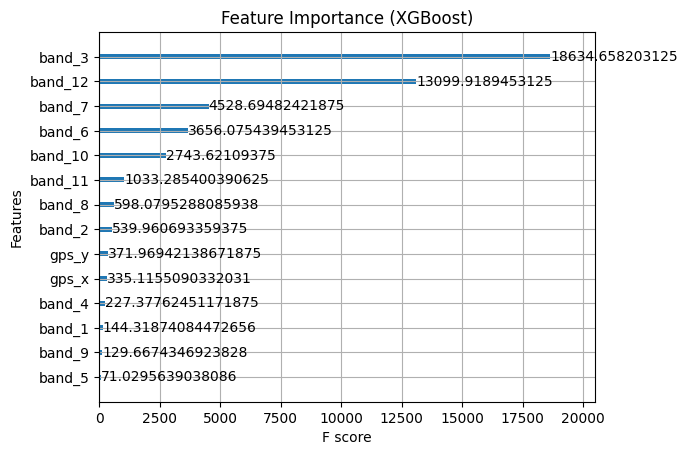

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt


# 2. Train/Validation split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Train XGBoost
xgb_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

xgb_clf.fit(X_train, y_train)

# 4. Predict on validation set
y_pred = xgb_clf.predict(X_val)

# 5. Evaluate
print("📊 Classification Report (Validation Set):")
print(classification_report(y_val, y_pred))

print(f"✅ Accuracy (Validation Set): {accuracy_score(y_val, y_pred):.4f}")

# 6. Plot Feature Importance
xgb.plot_importance(xgb_clf, max_num_features=15, importance_type='gain')
plt.title('Feature Importance (XGBoost)')
plt.show()


In [ ]:
# Select most important features manually
important_features = ['band_12', 'band_7', 'band_3', 'band_6']

X_important = df[important_features]

In [ ]:
# Split again
X_train_imp, X_val_imp, y_train_imp, y_val_imp = train_test_split(
    X_important, y, test_size=0.2, stratify=y, random_state=42
)

# Train XGBoost again
xgb_clf_imp = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)

xgb_clf_imp.fit(X_train_imp, y_train_imp)

# Predict
y_pred_imp = xgb_clf_imp.predict(X_val_imp)

# Evaluate
print("📊 Classification Report (Important Features Only):")
print(classification_report(y_val_imp, y_pred_imp))

print(f"✅ Accuracy (Important Features Only): {accuracy_score(y_val_imp, y_pred_imp):.4f}")

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [22:47:47] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


📊 Classification Report (Important Features Only):
              precision    recall  f1-score   support

           0       0.99      0.99      0.99    600000
           1       0.99      0.99      0.99    600000

    accuracy                           0.99   1200000
   macro avg       0.99      0.99      0.99   1200000
weighted avg       0.99      0.99      0.99   1200000

✅ Accuracy (Important Features Only): 0.9905


In [ ]:
# --- 1. Load the test CSV ---
df_test = pd.read_csv('/content/drive/MyDrive/Clean_Data/TIARET_Clean.csv')

In [ ]:
df_test.shape

(1500000, 15)

In [ ]:
df_test = df_test.dropna()
df_test.shape

(1500000, 15)

In [ ]:
# --- 1. Filter test data to keep only labels 0 and 1 ---
df_test = df_test[df_test['label'].isin([0, 1])]

# --- 2. Separate features and label ---
X_test_full = df_test.drop(columns=['label'])
y_test_full = df_test['label']

print("✅ Loaded test data:", X_test_full.shape)

# --- 3. Select the same important features for the test data ---
important_features = ['band_12', 'band_7', 'band_3', 'band_6']  # just to be sure it's defined here
X_test_imp = X_test_full[important_features]

# --- 4. Predict with your trained final model ---
y_pred_test = xgb_clf_imp.predict(X_test_imp)

# --- 5. Evaluate ---
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("📊 Evaluation on Final Test CSV:")
print(classification_report(y_test_full, y_pred_test))
print("✅ Accuracy:", accuracy_score(y_test_full, y_pred_test))
print("🧮 Confusion Matrix:")
print(confusion_matrix(y_test_full, y_pred_test))


✅ Loaded test data: (1500000, 14)
📊 Evaluation on Final Test CSV:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98    750000
           1       0.98      0.98      0.98    750000

    accuracy                           0.98   1500000
   macro avg       0.98      0.98      0.98   1500000
weighted avg       0.98      0.98      0.98   1500000

✅ Accuracy: 0.983006
🧮 Confusion Matrix:
[[737416  12584]
 [ 12907 737093]]


# Model Testing
###

In [9]:
from google.colab import drive
drive.mount('/content/drive')
folder = "/content/drive/MyDrive/Validation_data"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install rasterio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 25.8 MB/s eta 0:00:00


In [3]:
import os
import rasterio
import pandas as pd
import numpy as np

# Paths
tif_folder = '/content/drive/MyDrive/Validation_data'   # 🔥 update this with your real folder path
csv_folder = '/content/drive/MyDrive/Test_Csv'

# Create output folder if it doesn't exist
os.makedirs(csv_folder, exist_ok=True)

# Columns as you requested
columns = [
    'band_1', 'band_2', 'band_3', 'band_4',
    'band_5', 'band_6', 'band_7', 'band_8',
    'band_9', 'band_10', 'band_11', 'band_12'
]

# Loop through all .tif files
for filename in os.listdir(tif_folder):
    if filename.endswith('.tif') or filename.endswith('.tiff'):
        tif_path = os.path.join(tif_folder, filename)

        with rasterio.open(tif_path) as src:
            bands = src.read()  # shape: (bands, height, width)

        n_bands, h, w = bands.shape
        print(f"Processing {filename}: bands={n_bands}, height={h}, width={w}")

        if n_bands != 12:
            raise ValueError(f"Error: {filename} does not have exactly 12 bands!")

        # Flatten the bands: (bands, height, width) -> (height*width, bands)
        flattened_bands = bands.reshape(n_bands, -1).T  # (h*w, 12)

        # Create X order (0, 1, 2, ..., total_pixels-1)
        X_order = np.arange(flattened_bands.shape[0])

        # Create DataFrame
        df = pd.DataFrame(flattened_bands, columns=columns)
        df['X'] = X_order  # Add X column

        # Save the DataFrame to CSV
        output_filename = filename.replace('.tif', '.csv').replace('.tiff', '.csv')
        output_path = os.path.join(csv_folder, output_filename)
        df.to_csv(output_path, index=False)

        print(f"Saved CSV to {output_path}")


Processing 1 (33).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (33).csv
Processing 1 (34).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (34).csv
Processing 1 (35).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (35).csv
Processing 1 (36).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (36).csv
Processing 1 (38).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (38).csv
Processing 1 (37).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (37).csv
Processing 1 (39).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (39).csv
Processing 1 (41).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (41).csv
Processing 1 (40).tif: bands=12, height=256, width=256
Saved CSV to /content/drive/MyDrive/Test_Csv/1 (40).csv
P

✅ Model loaded!
🖼️ Processing 1 (1).tif and 1 (1).csv


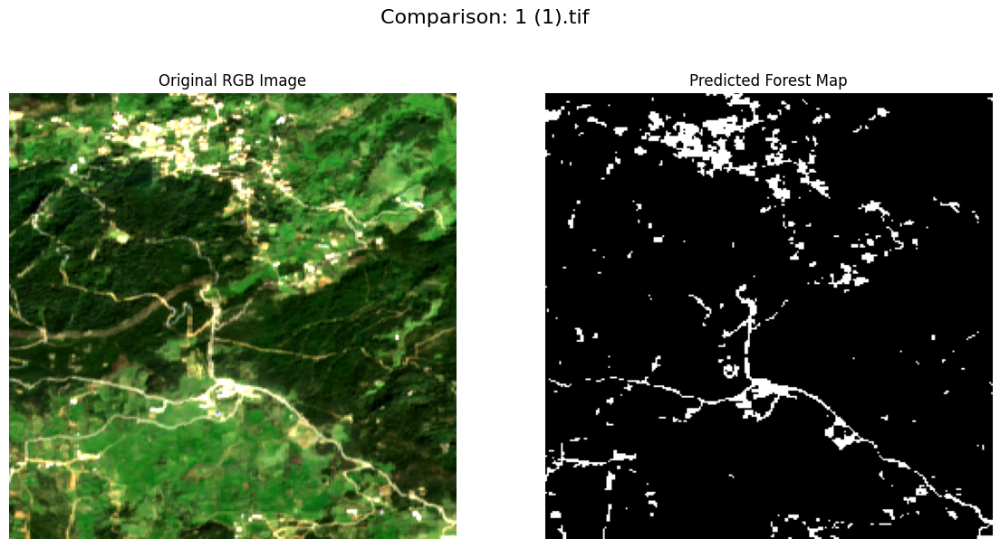

🖼️ Processing 1 (10).tif and 1 (10).csv


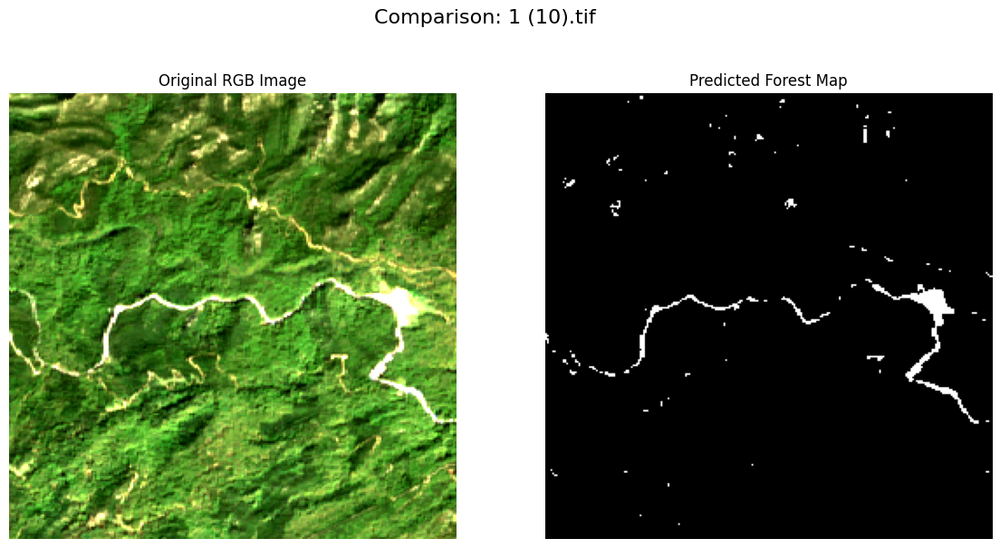

🖼️ Processing 1 (11).tif and 1 (11).csv


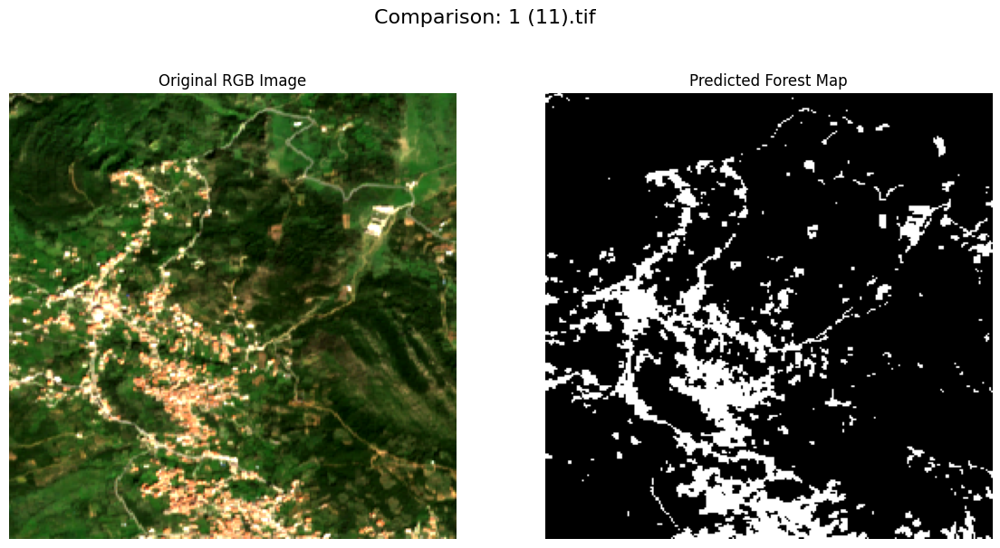

🖼️ Processing 1 (12).tif and 1 (12).csv


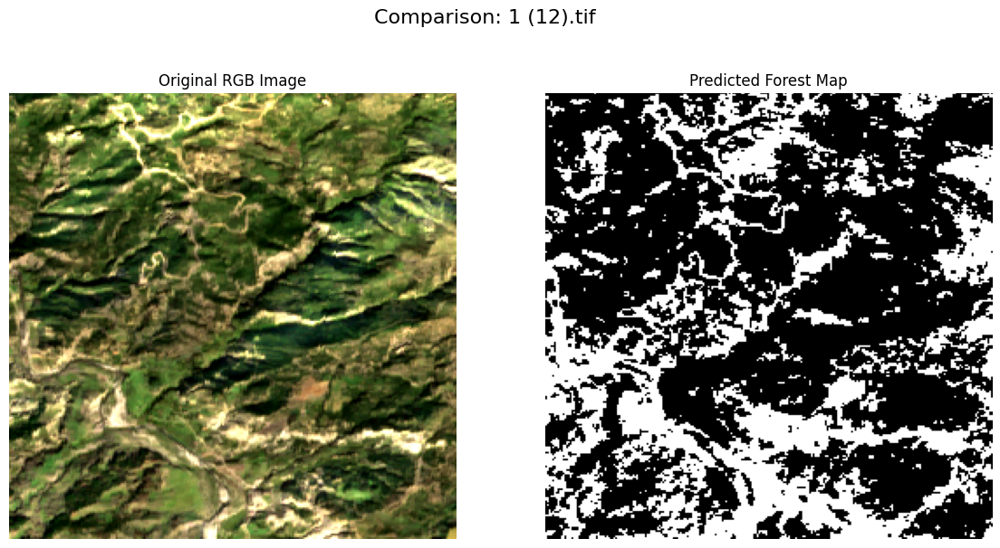

🖼️ Processing 1 (13).tif and 1 (13).csv


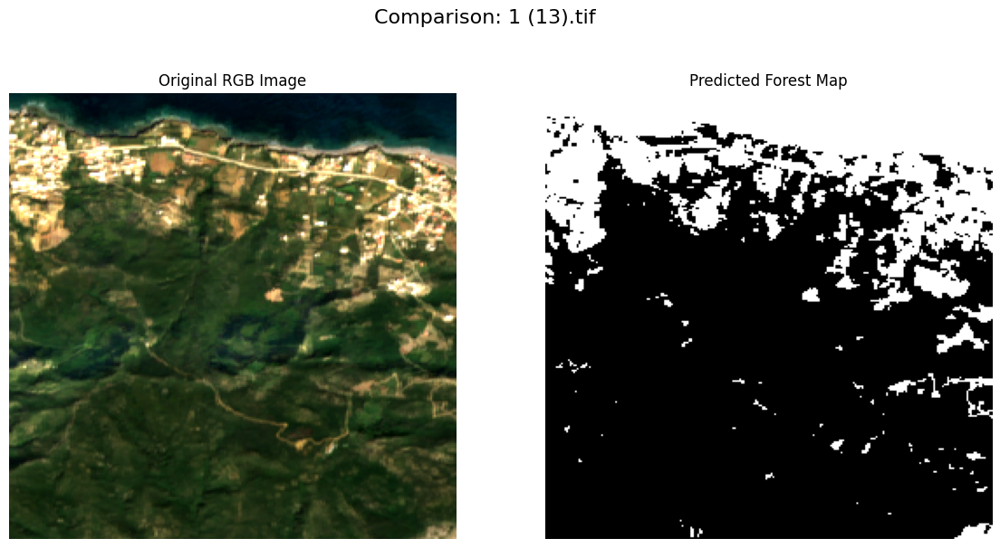

🖼️ Processing 1 (14).tif and 1 (14).csv


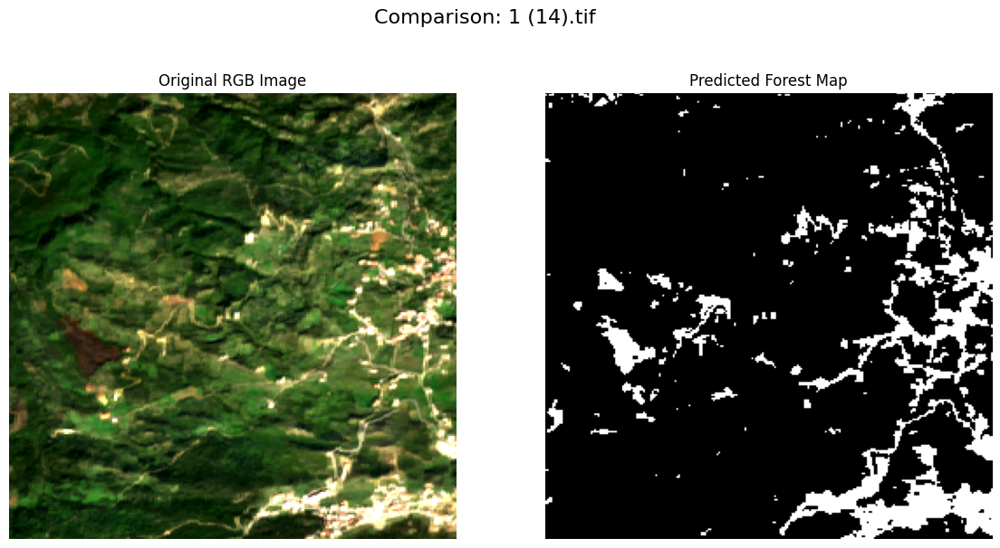

🖼️ Processing 1 (15).tif and 1 (15).csv


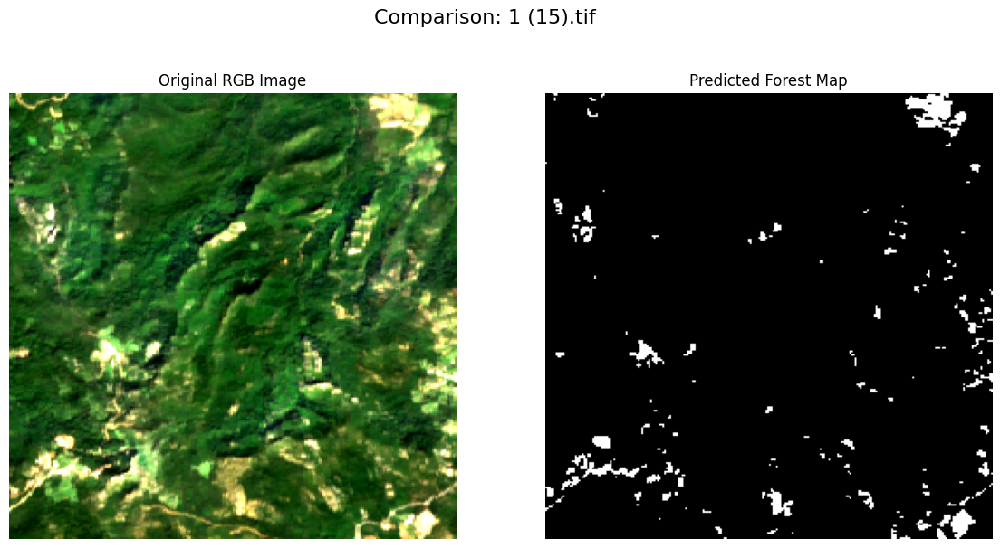

🖼️ Processing 1 (16).tif and 1 (16).csv


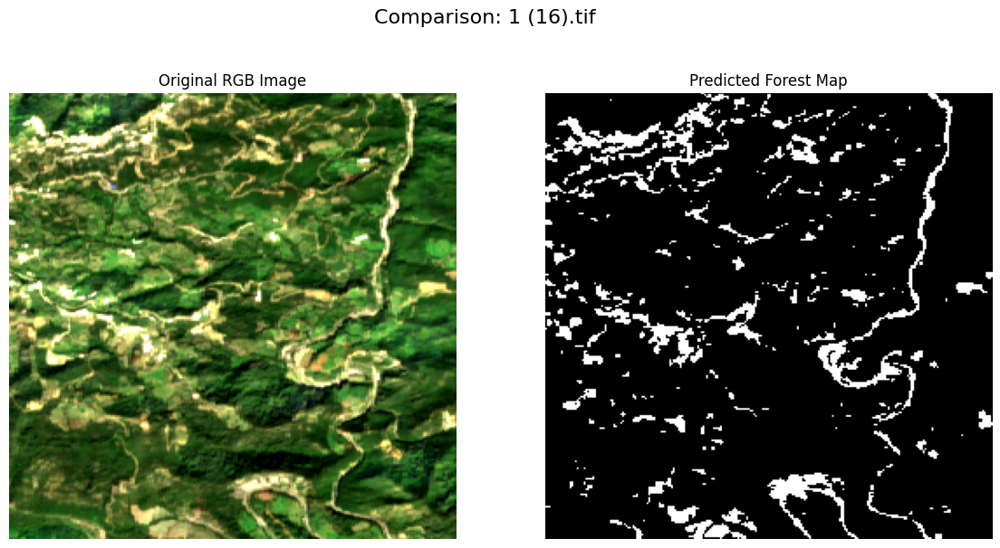

🖼️ Processing 1 (17).tif and 1 (17).csv


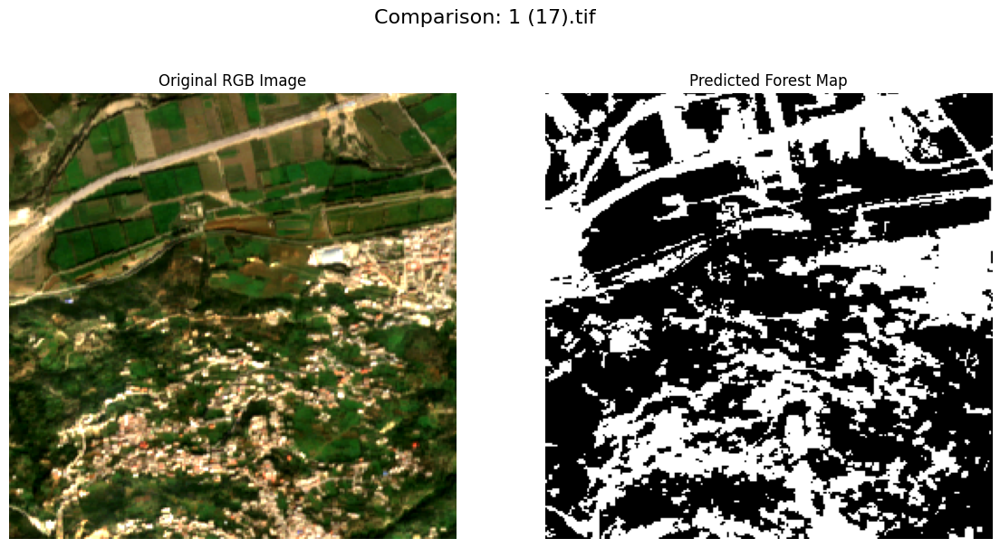

🖼️ Processing 1 (18).tif and 1 (18).csv


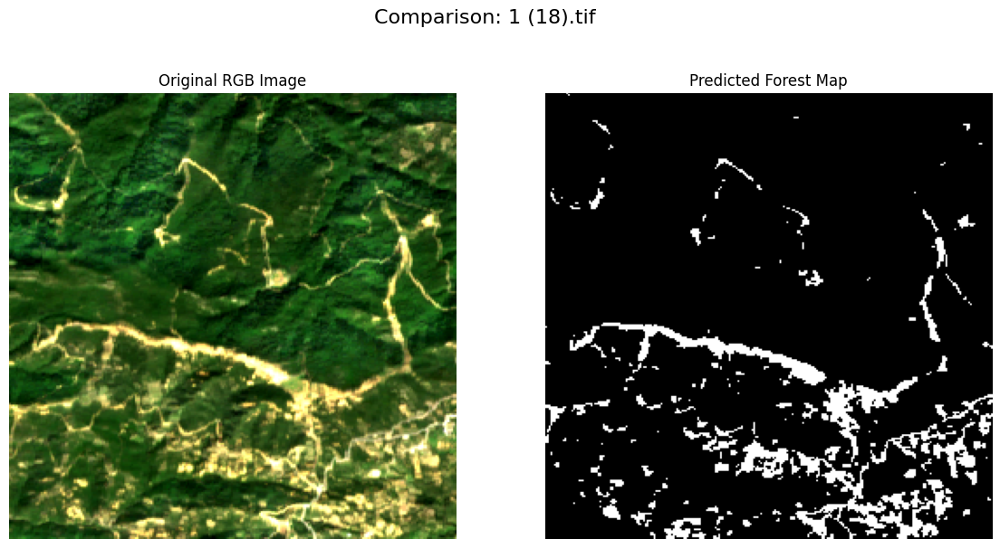

🖼️ Processing 1 (19).tif and 1 (19).csv


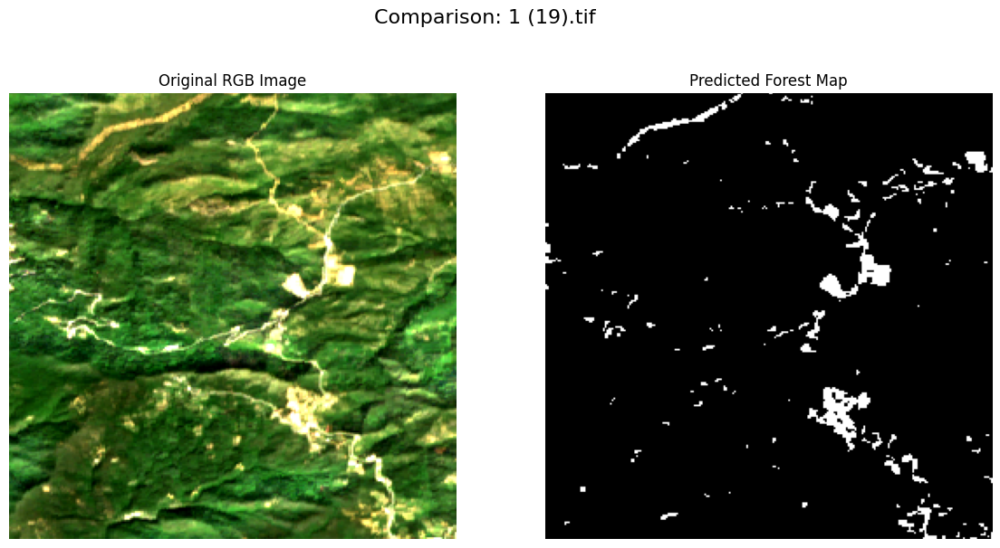

🖼️ Processing 1 (2).tif and 1 (2).csv


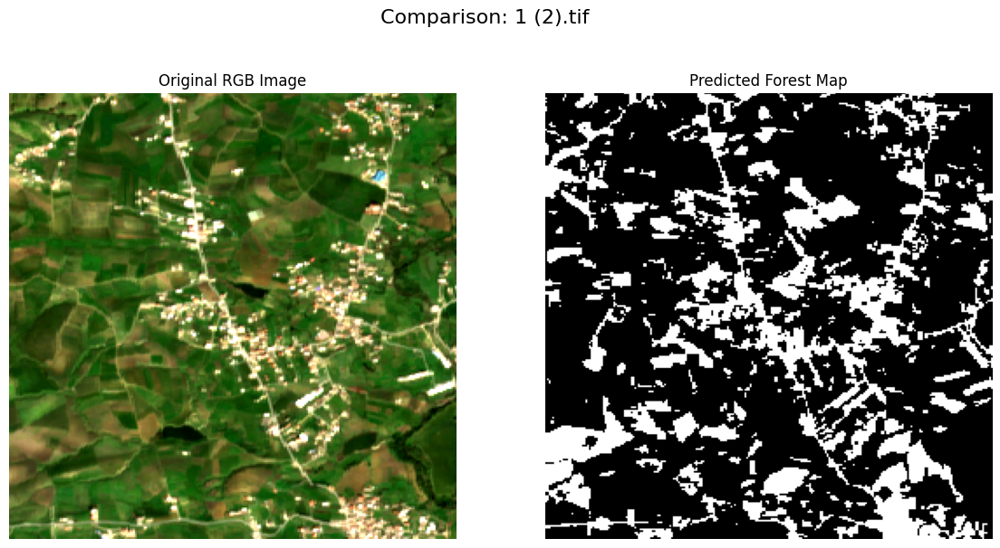

🖼️ Processing 1 (20).tif and 1 (20).csv


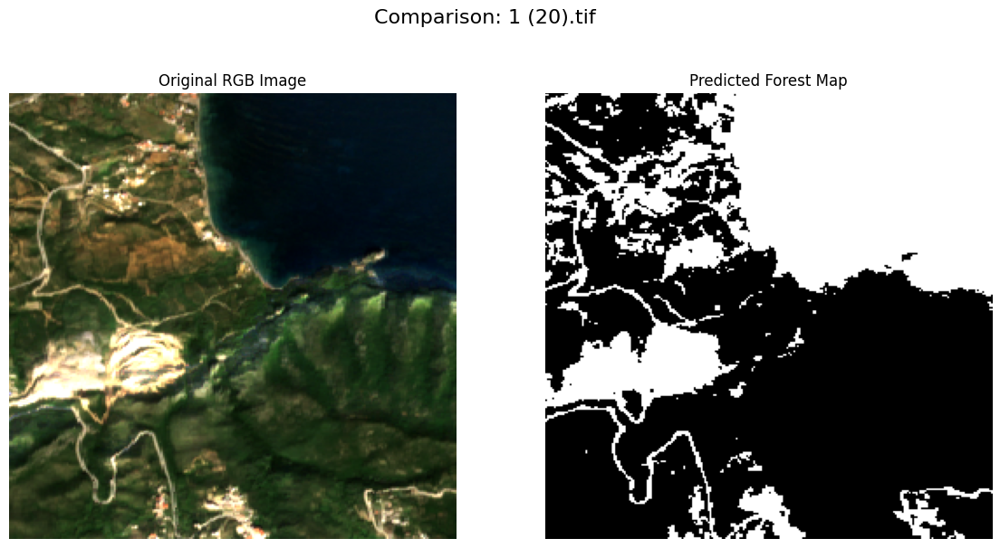

🖼️ Processing 1 (21).tif and 1 (21).csv


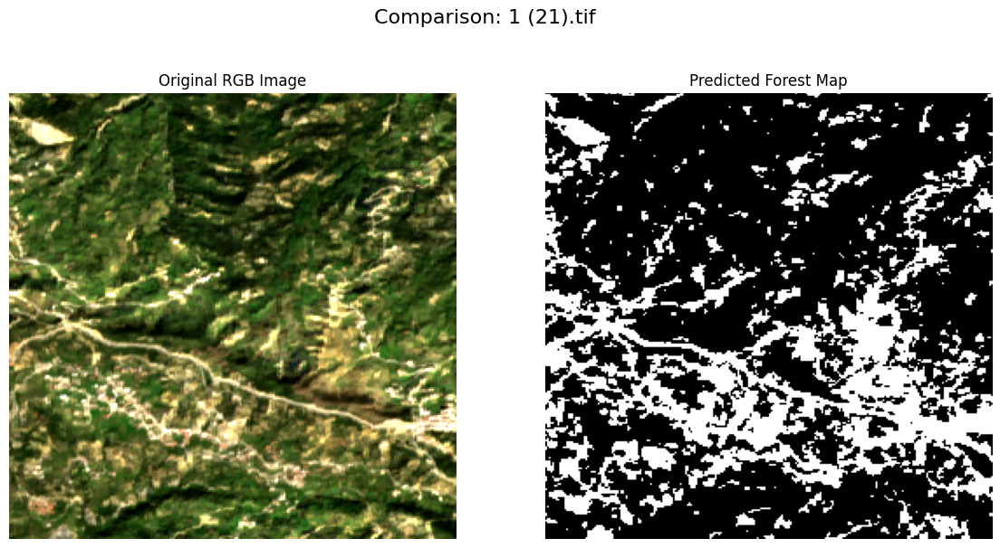

🖼️ Processing 1 (22).tif and 1 (22).csv


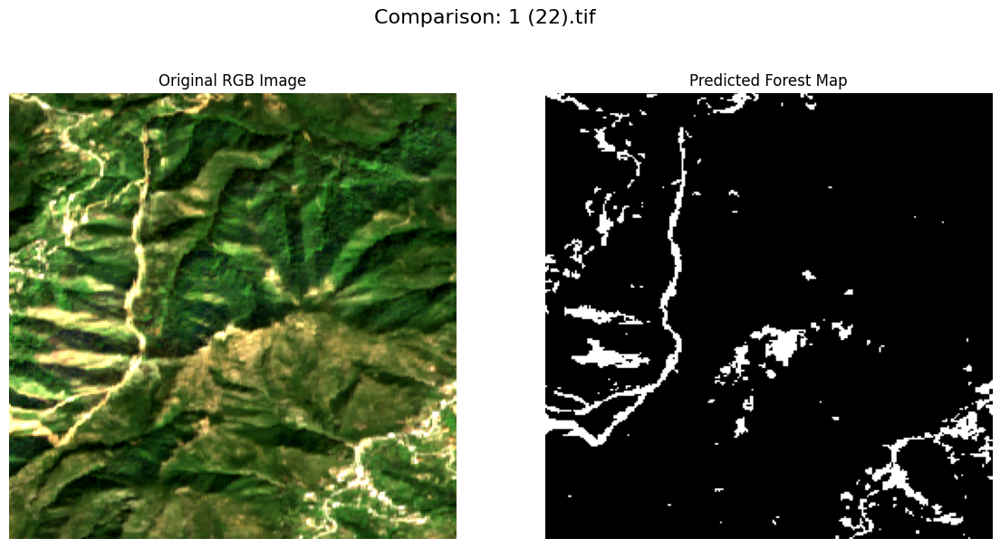

🖼️ Processing 1 (23).tif and 1 (23).csv


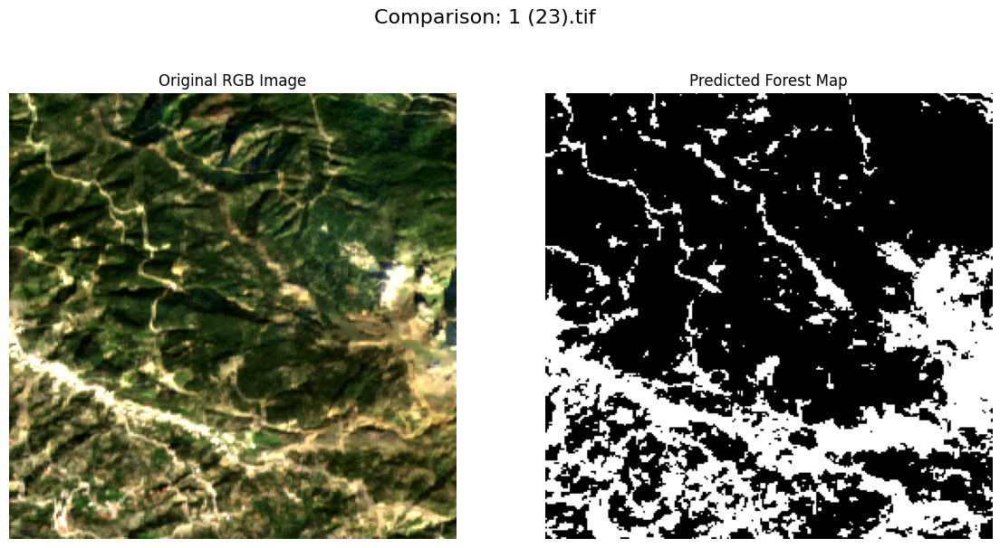

🖼️ Processing 1 (24).tif and 1 (24).csv


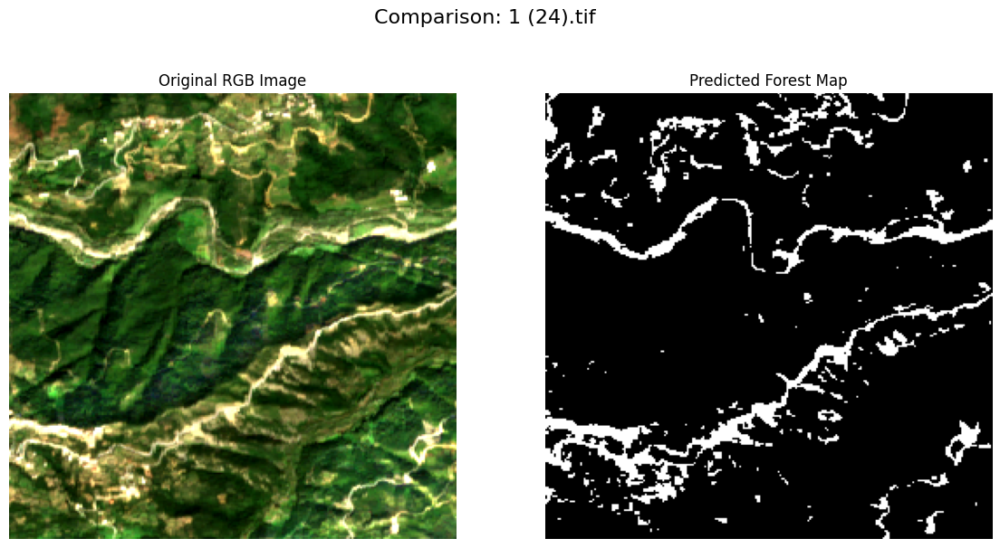

🖼️ Processing 1 (25).tif and 1 (25).csv


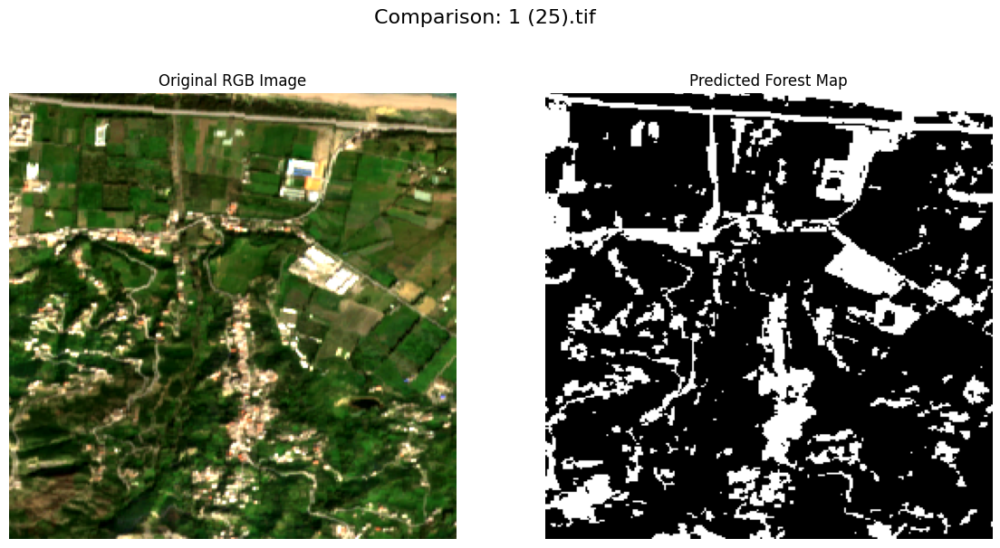

🖼️ Processing 1 (26).tif and 1 (26).csv


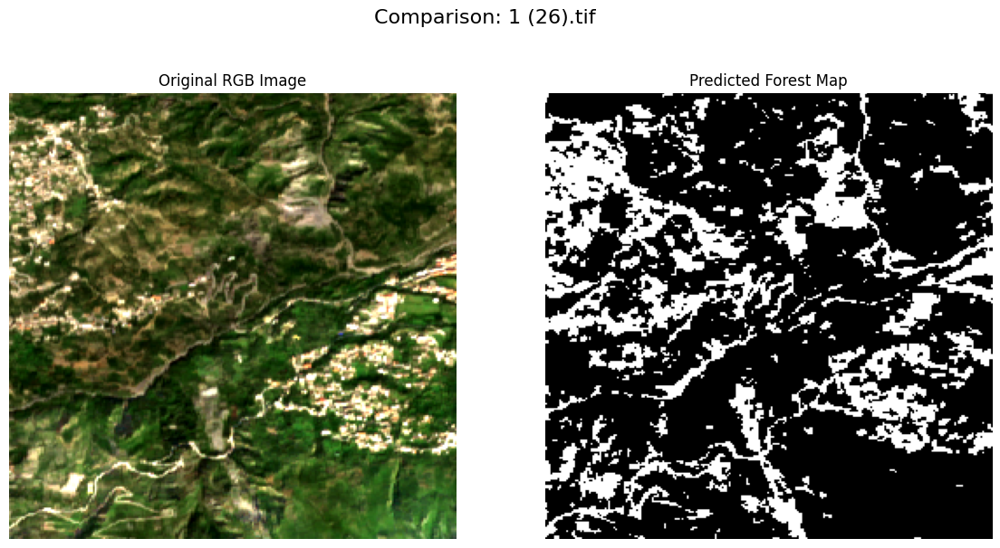

🖼️ Processing 1 (27).tif and 1 (27).csv


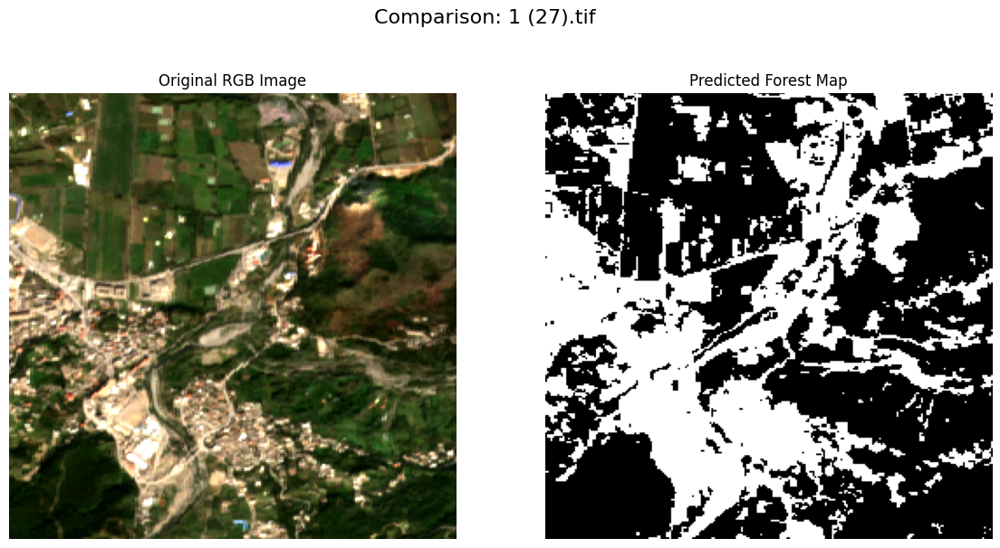

🖼️ Processing 1 (28).tif and 1 (28).csv


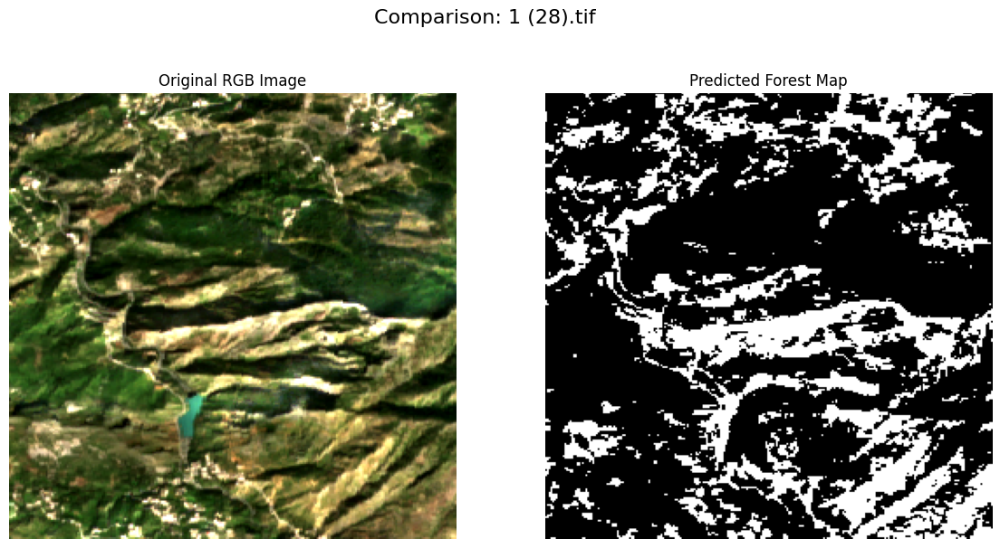

🖼️ Processing 1 (29).tif and 1 (29).csv


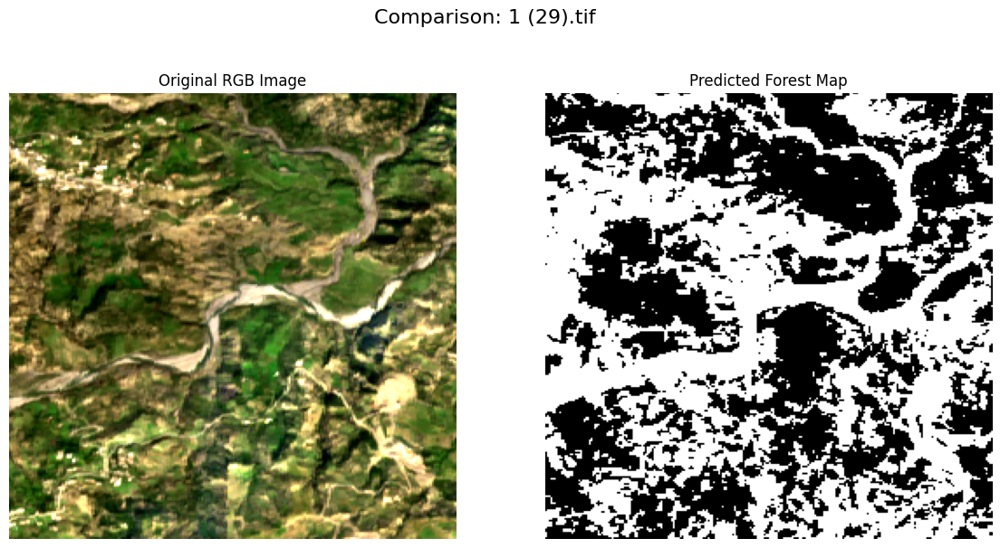

🖼️ Processing 1 (3).tif and 1 (3).csv


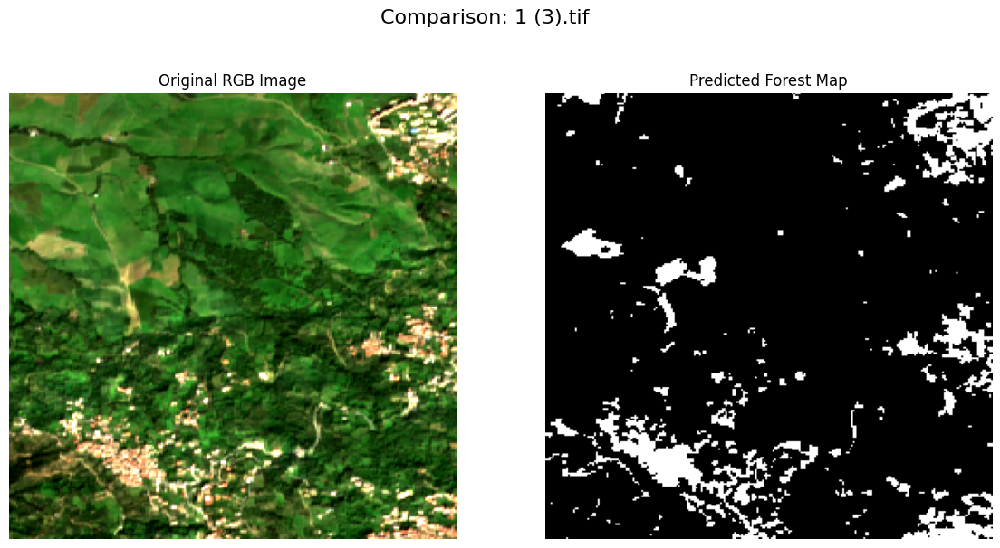

🖼️ Processing 1 (30).tif and 1 (30).csv


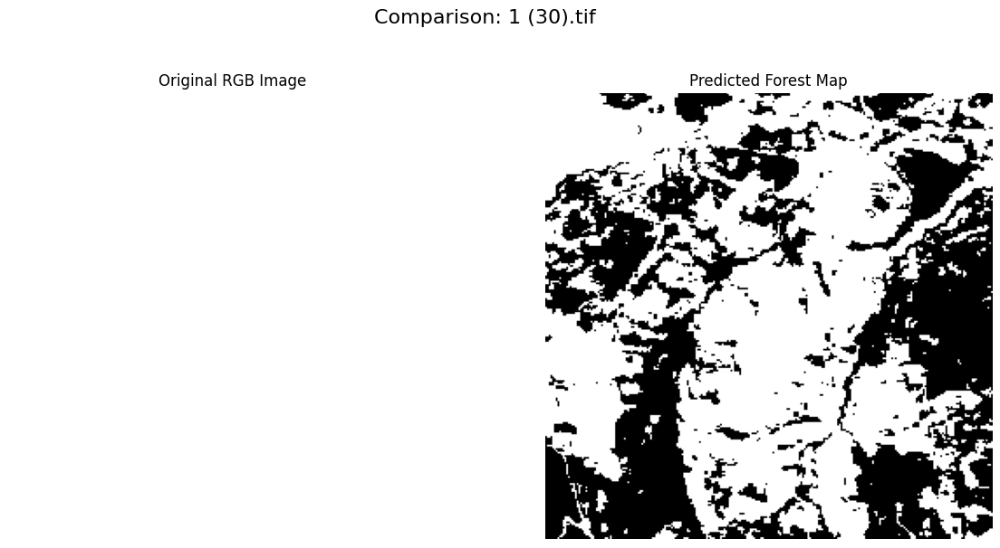

🖼️ Processing 1 (31).tif and 1 (31).csv


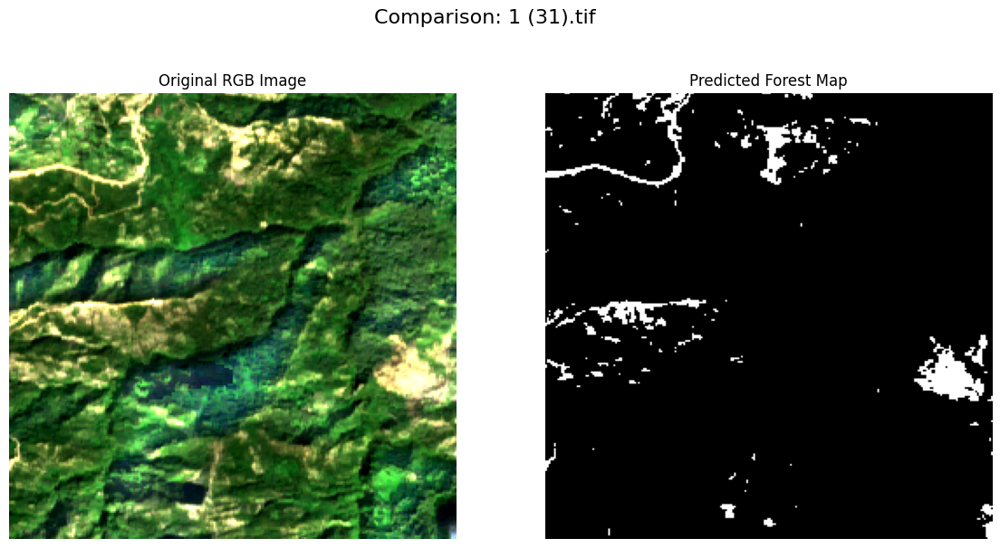

🖼️ Processing 1 (32).tif and 1 (32).csv


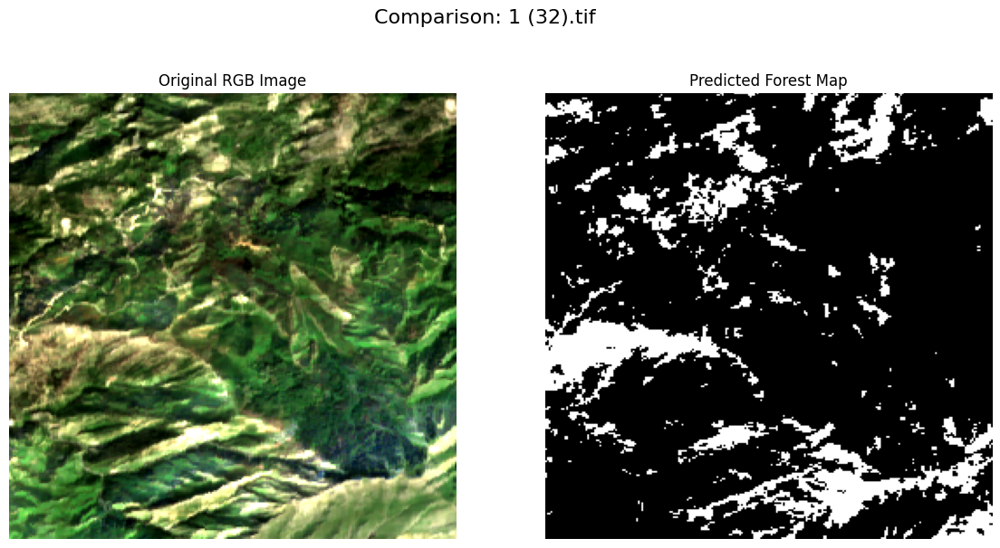

🖼️ Processing 1 (33).tif and 1 (33).csv


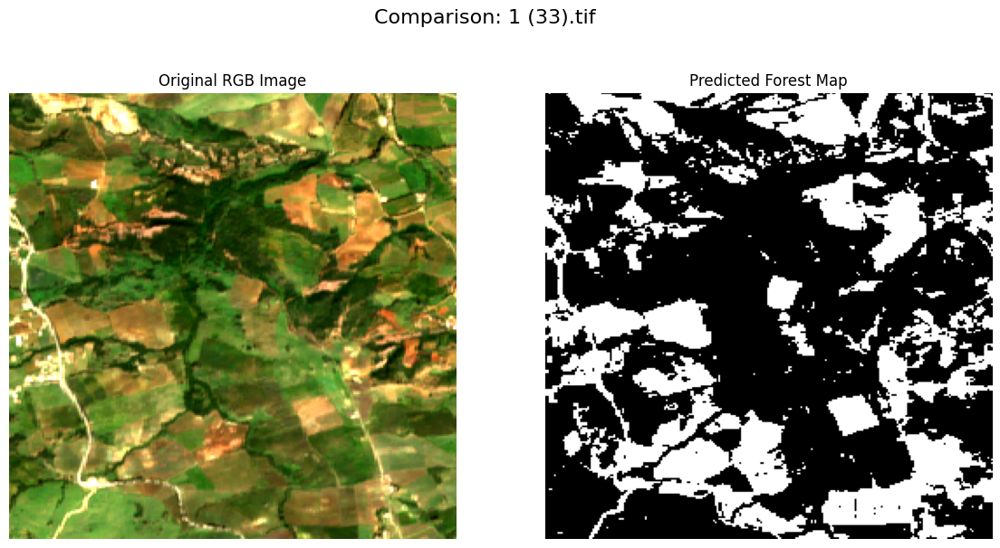

🖼️ Processing 1 (34).tif and 1 (34).csv


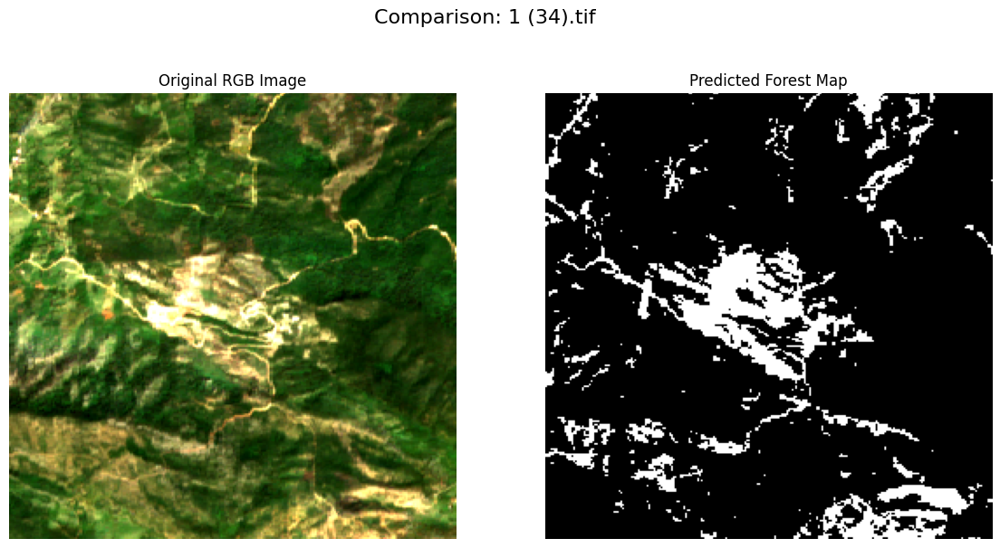

🖼️ Processing 1 (35).tif and 1 (35).csv


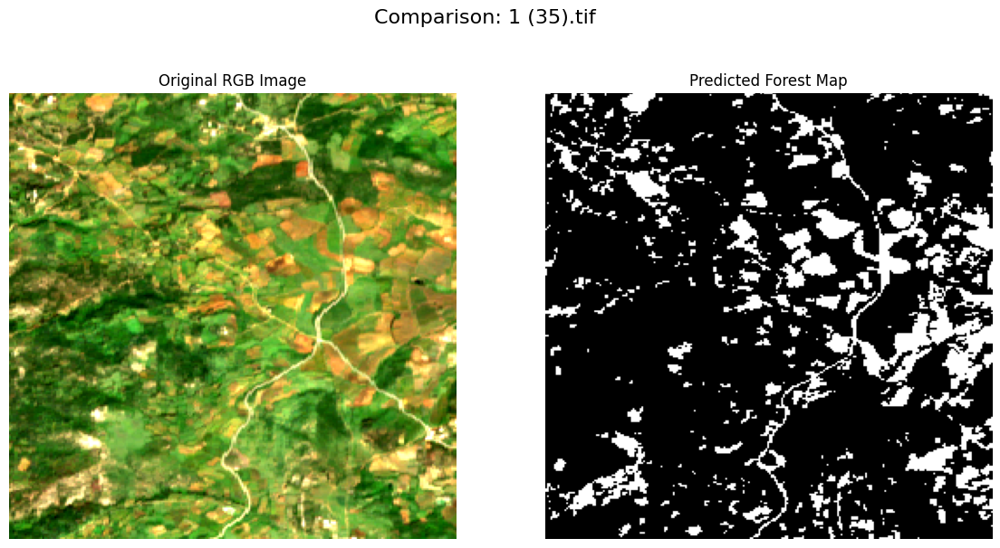

🖼️ Processing 1 (36).tif and 1 (36).csv


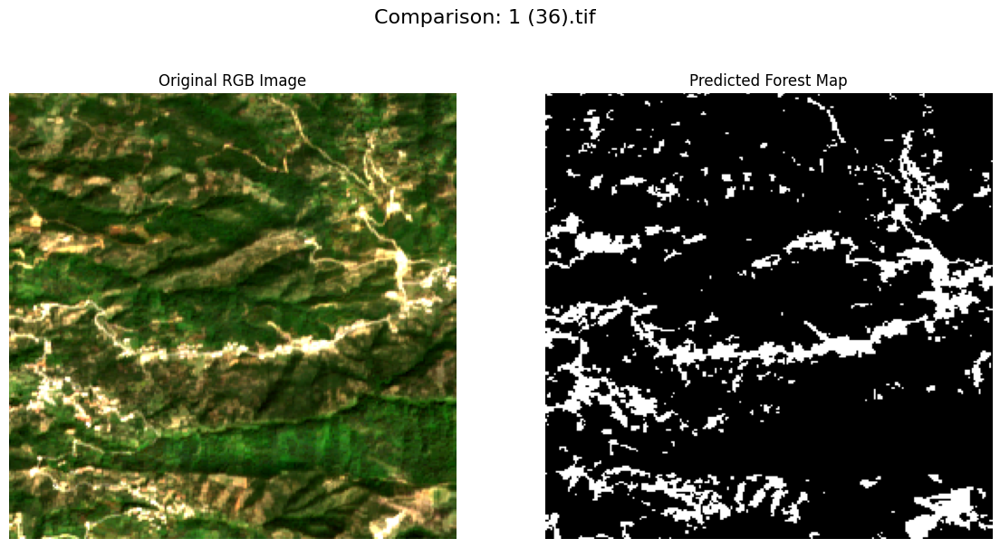

🖼️ Processing 1 (37).tif and 1 (37).csv


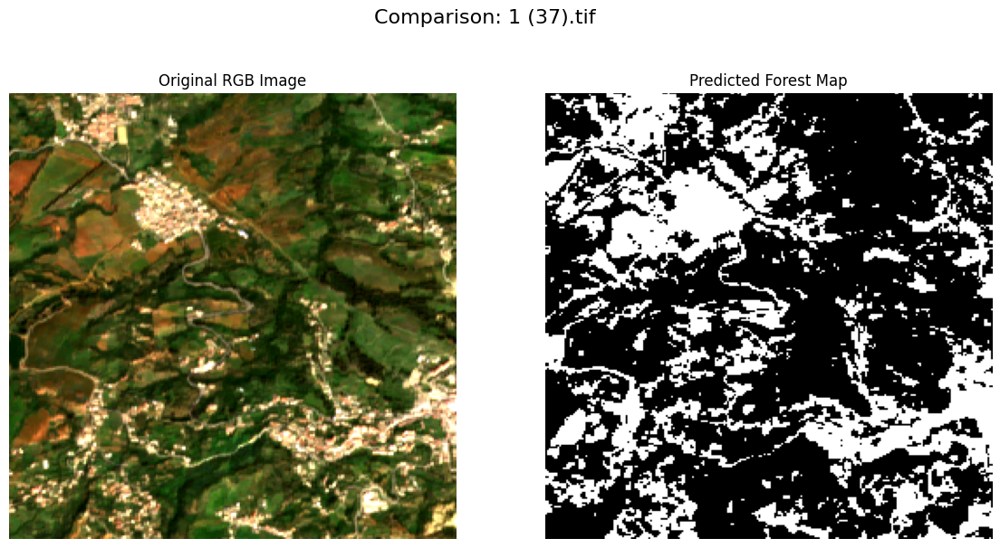

🖼️ Processing 1 (38).tif and 1 (38).csv


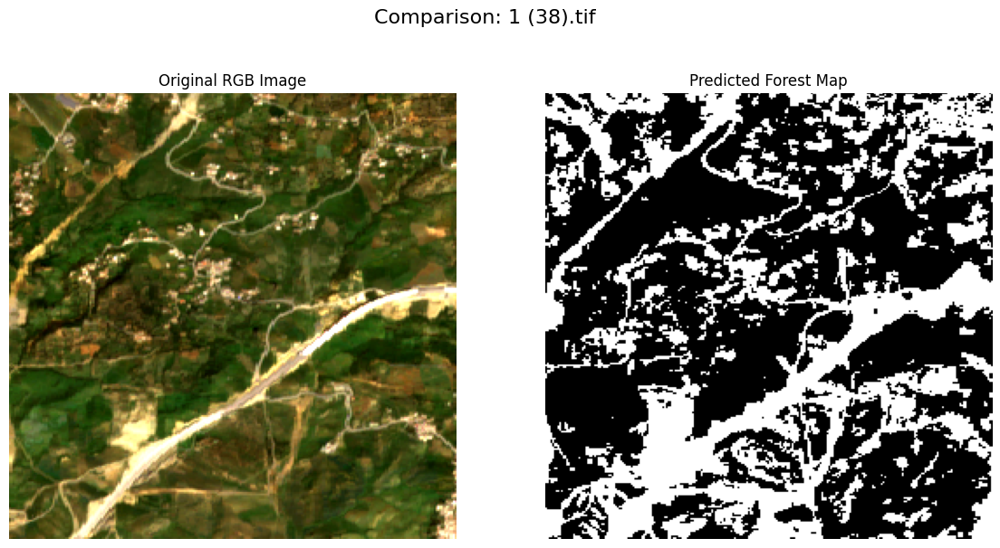

🖼️ Processing 1 (39).tif and 1 (39).csv


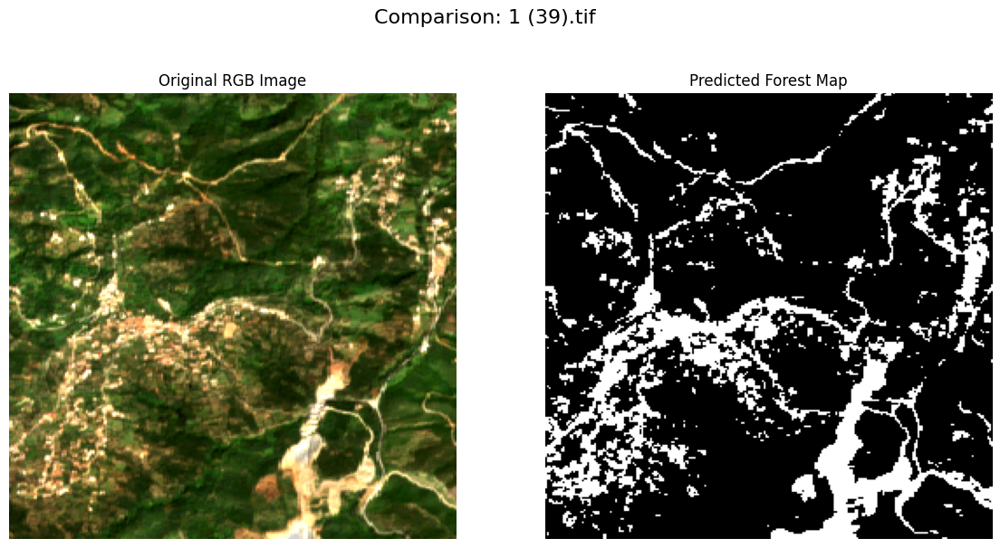

🖼️ Processing 1 (4).tif and 1 (4).csv


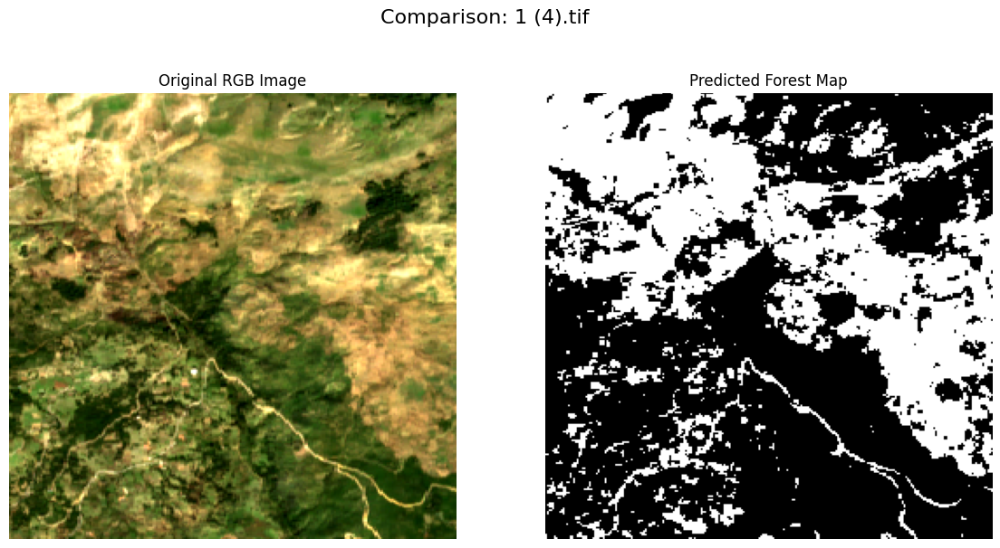

🖼️ Processing 1 (40).tif and 1 (40).csv


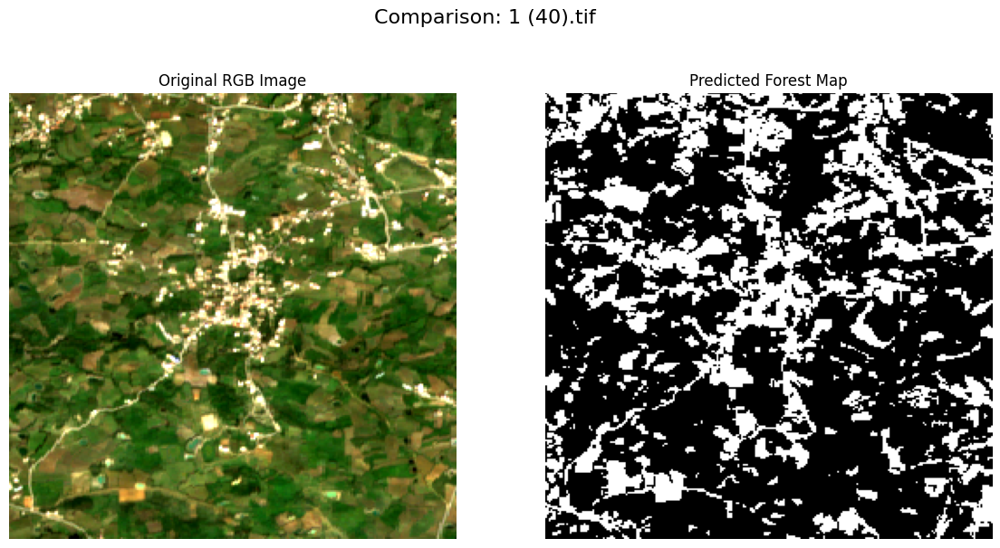

🖼️ Processing 1 (41).tif and 1 (41).csv


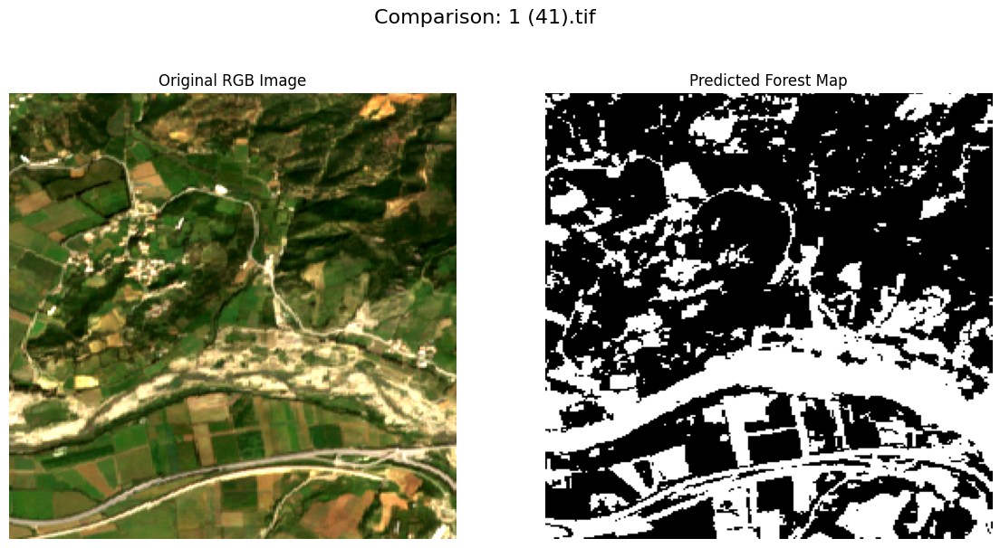

🖼️ Processing 1 (42).tif and 1 (42).csv


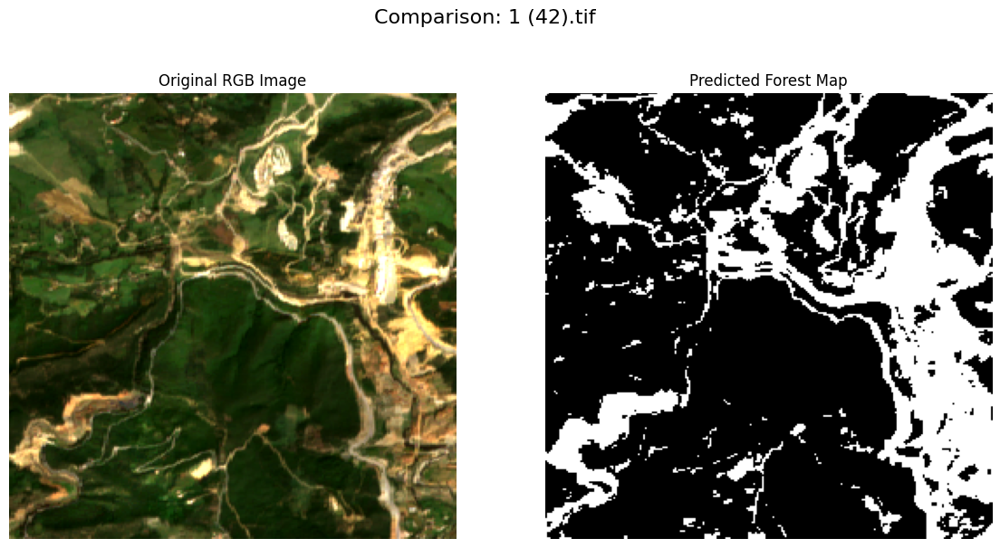

🖼️ Processing 1 (43).tif and 1 (43).csv


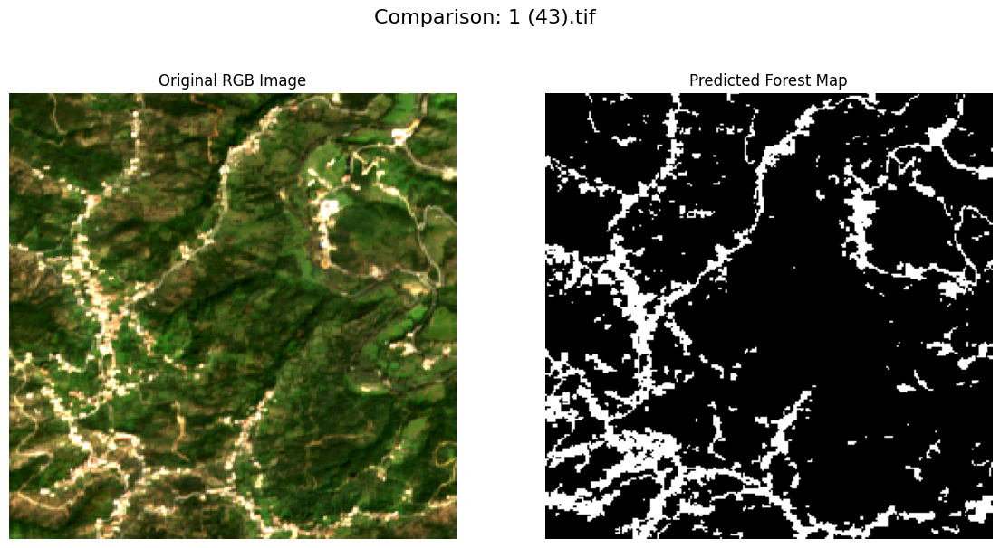

🖼️ Processing 1 (44).tif and 1 (44).csv


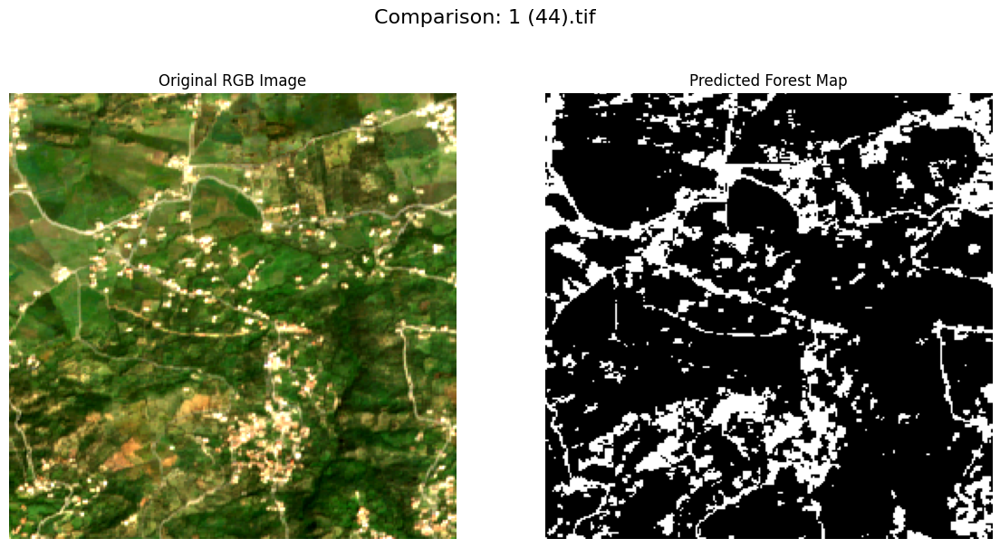

🖼️ Processing 1 (45).tif and 1 (45).csv


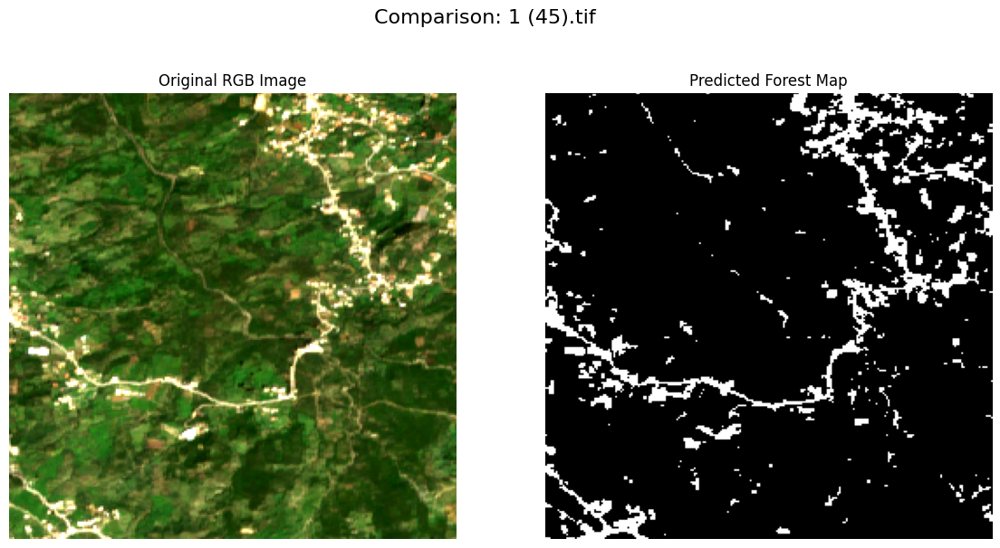

🖼️ Processing 1 (46).tif and 1 (46).csv


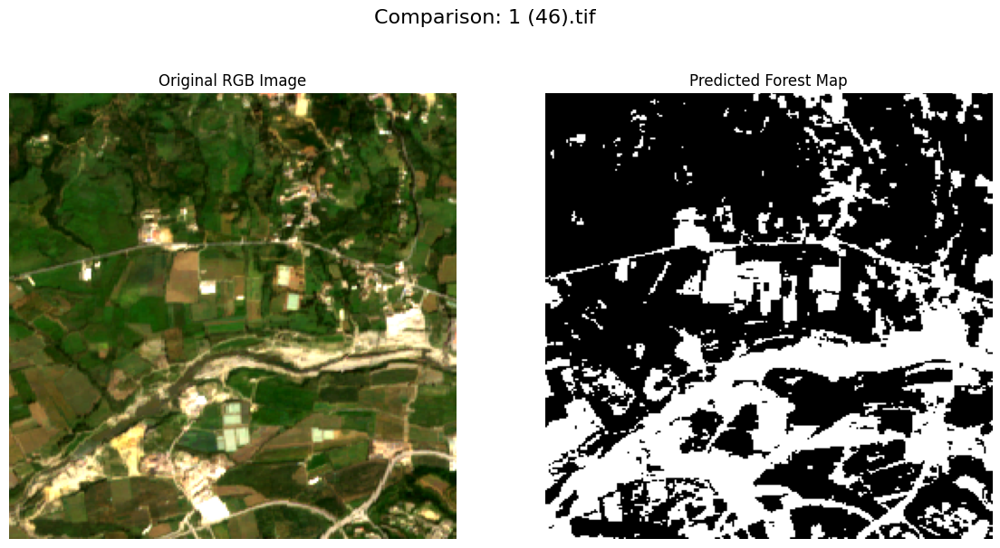

🖼️ Processing 1 (47).tif and 1 (47).csv


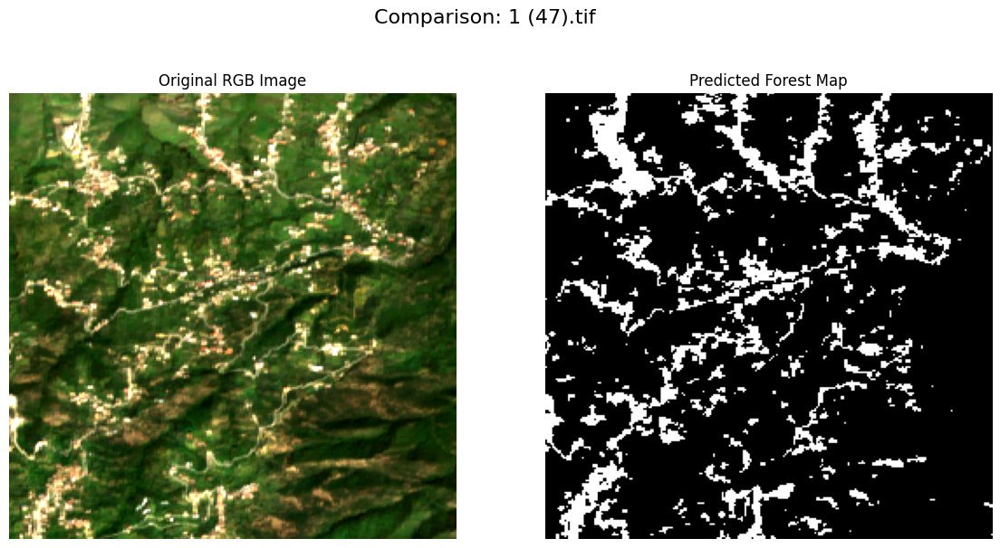

🖼️ Processing 1 (48).tif and 1 (48).csv


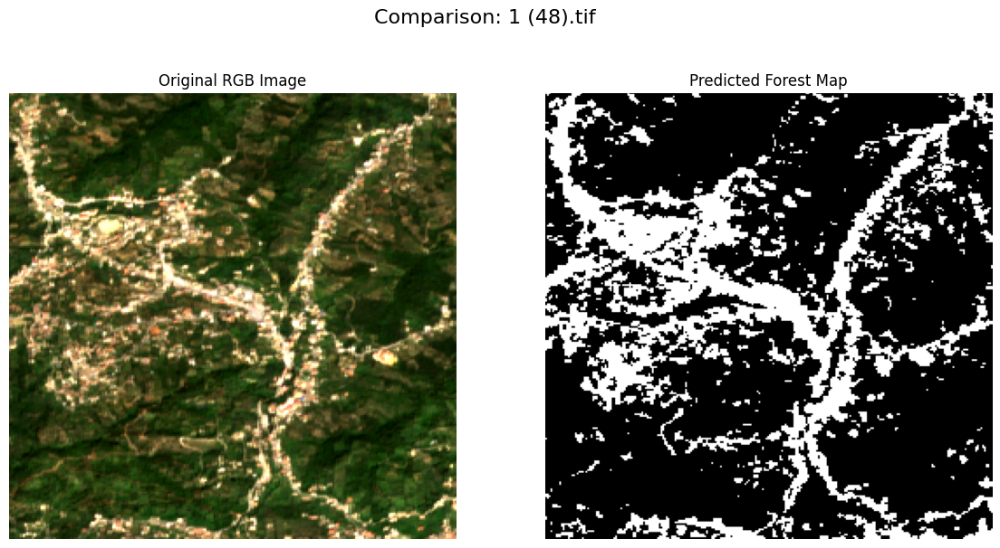

🖼️ Processing 1 (49).tif and 1 (49).csv


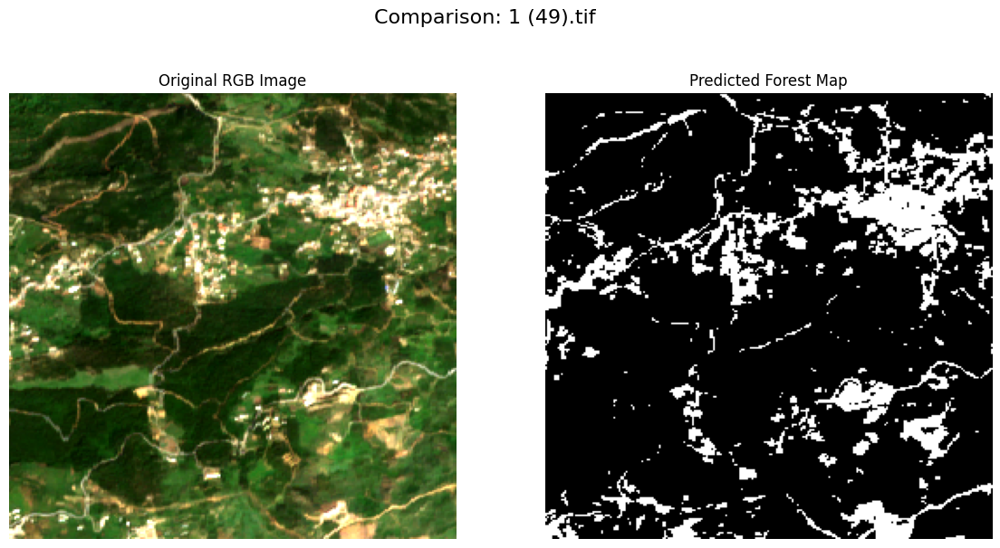

🖼️ Processing 1 (5).tif and 1 (5).csv


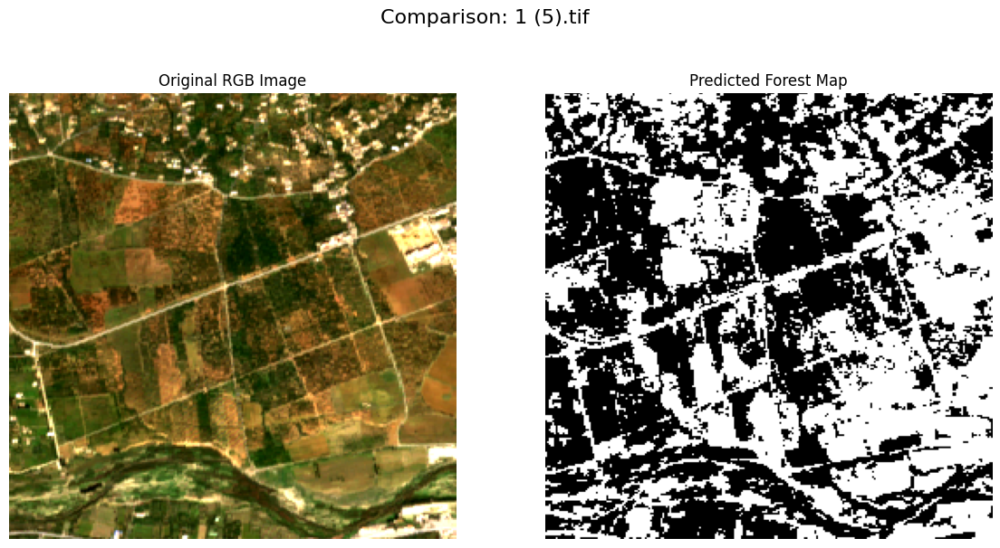

🖼️ Processing 1 (50).tif and 1 (50).csv


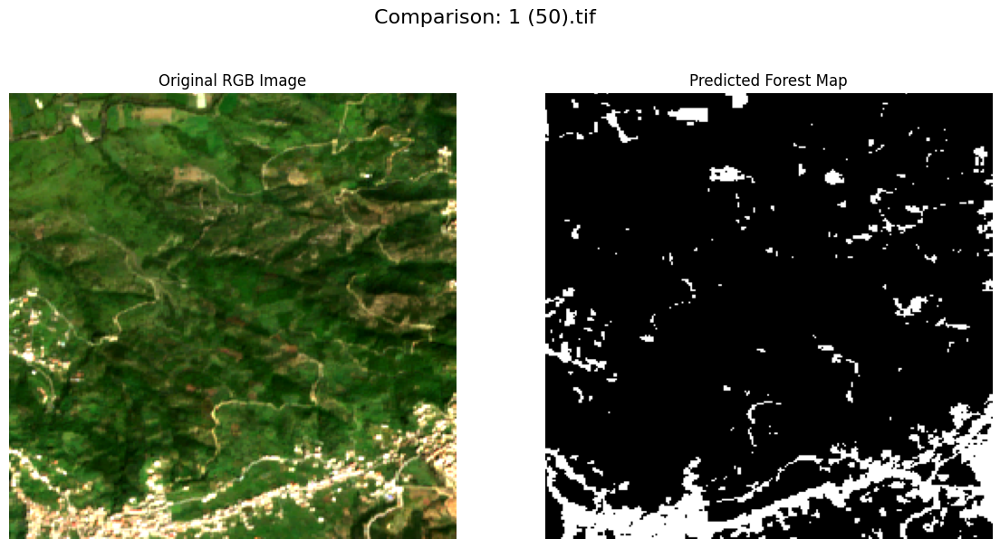

🖼️ Processing 1 (51).tif and 1 (51).csv


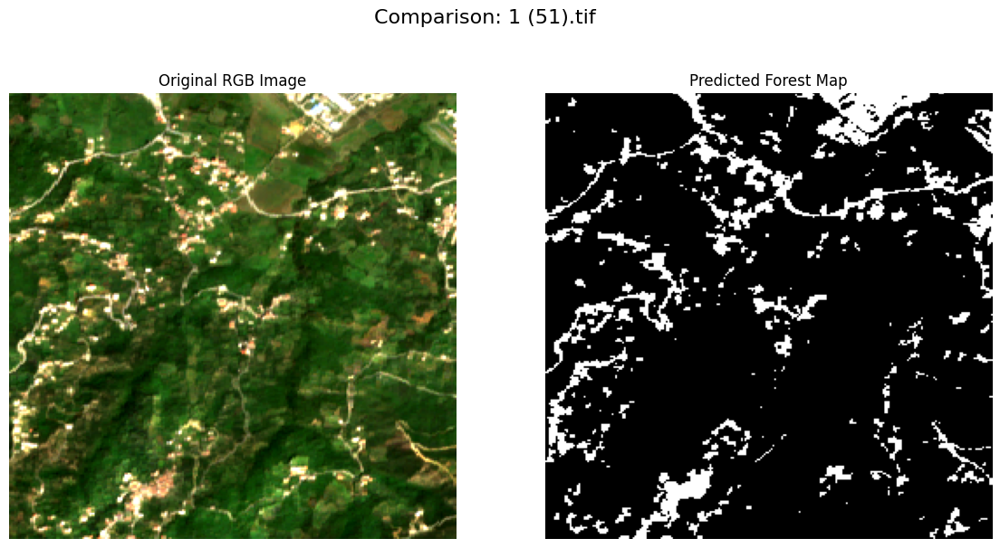

🖼️ Processing 1 (52).tif and 1 (52).csv


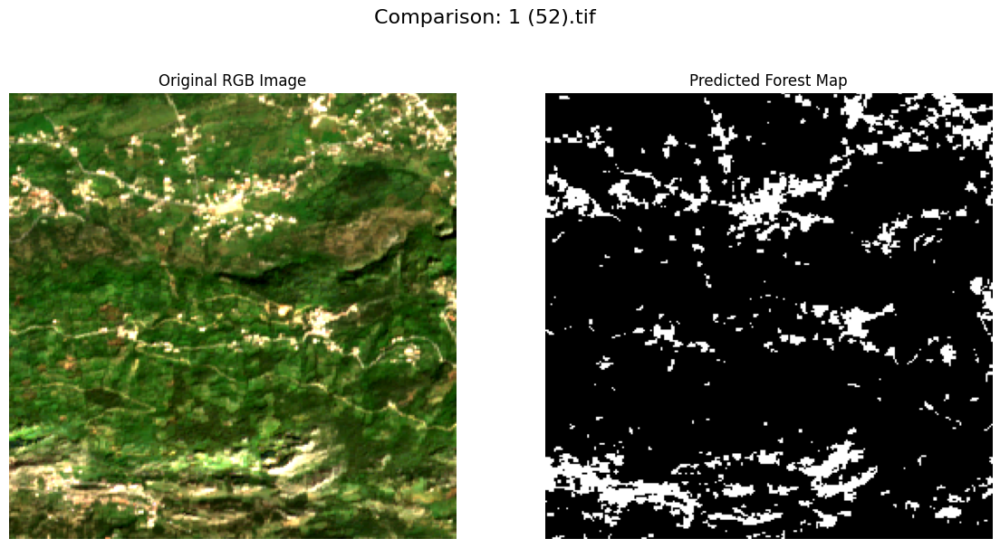

🖼️ Processing 1 (53).tif and 1 (53).csv


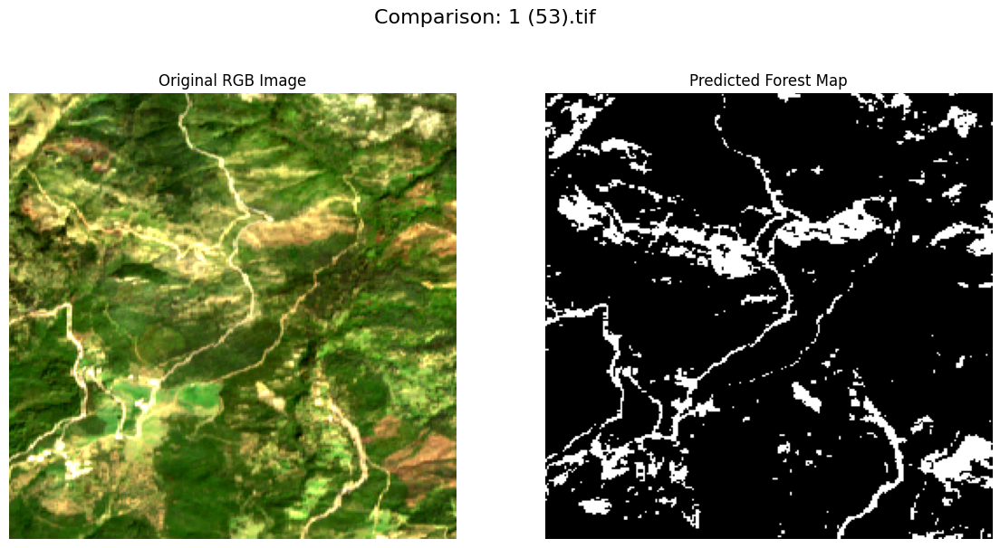

🖼️ Processing 1 (54).tif and 1 (54).csv


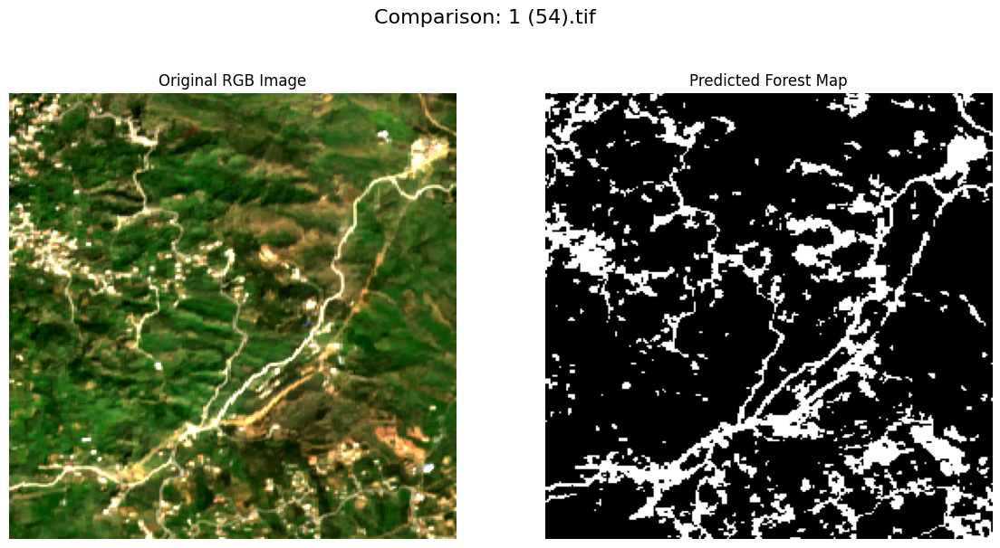

🖼️ Processing 1 (55).tif and 1 (55).csv


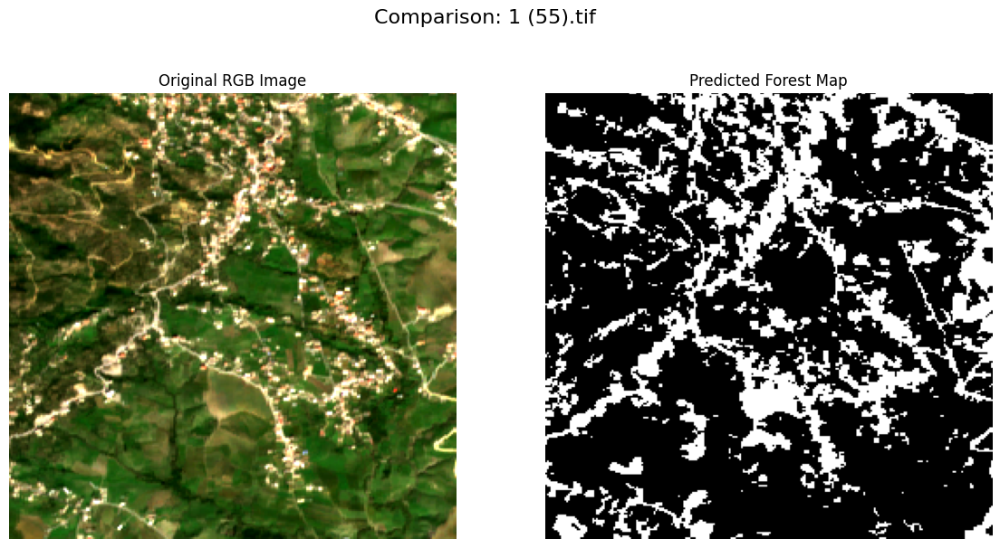

🖼️ Processing 1 (56).tif and 1 (56).csv


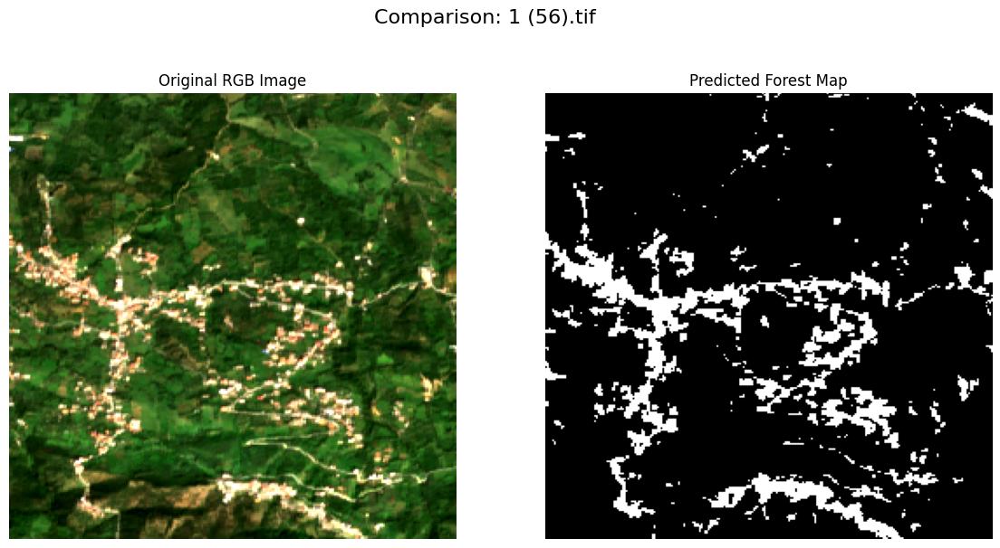

🖼️ Processing 1 (57).tif and 1 (57).csv


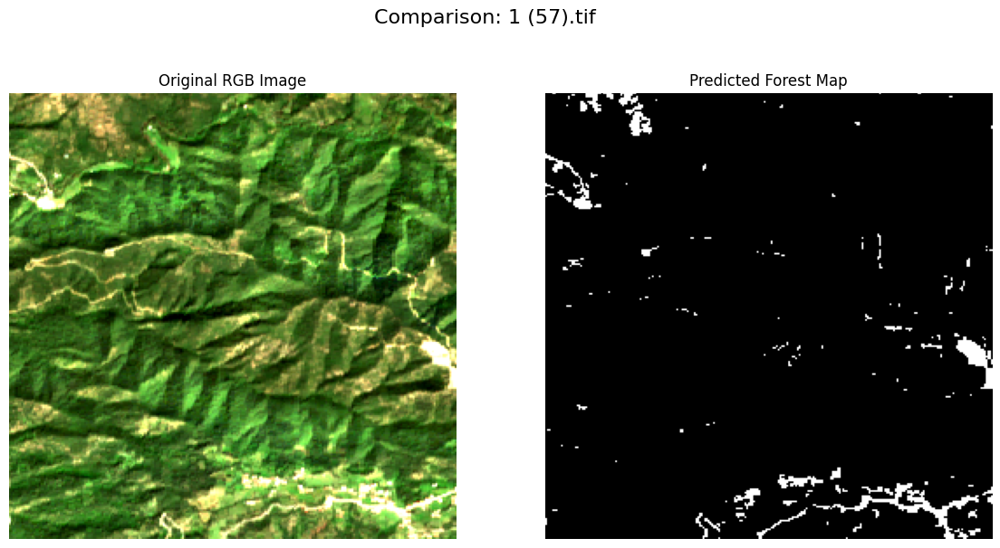

🖼️ Processing 1 (58).tif and 1 (58).csv


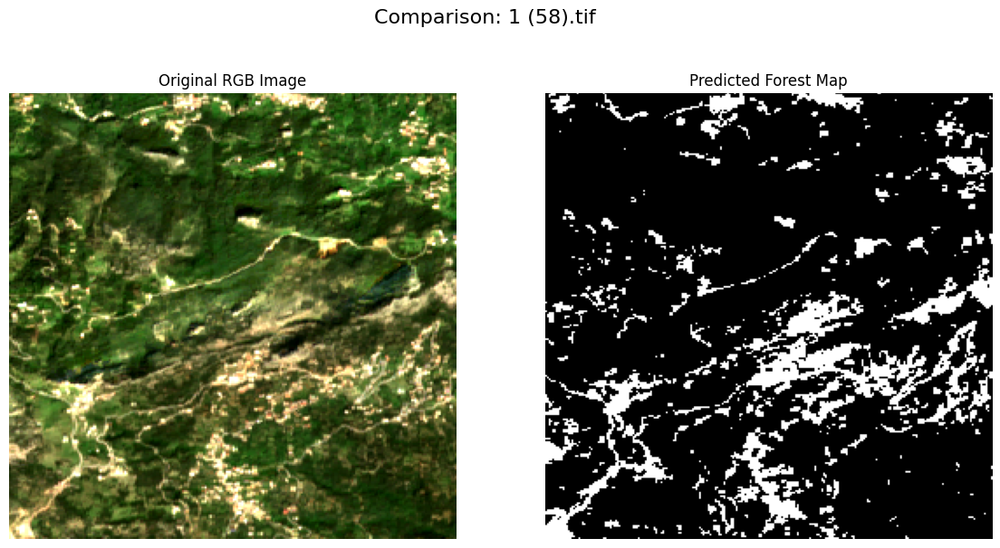

🖼️ Processing 1 (6).tif and 1 (6).csv


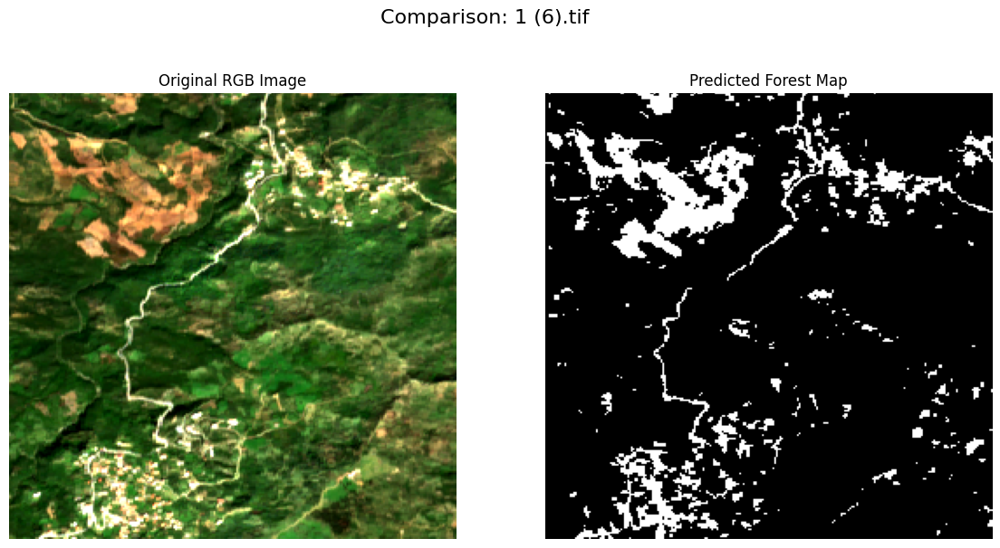

🖼️ Processing 1 (7).tif and 1 (7).csv


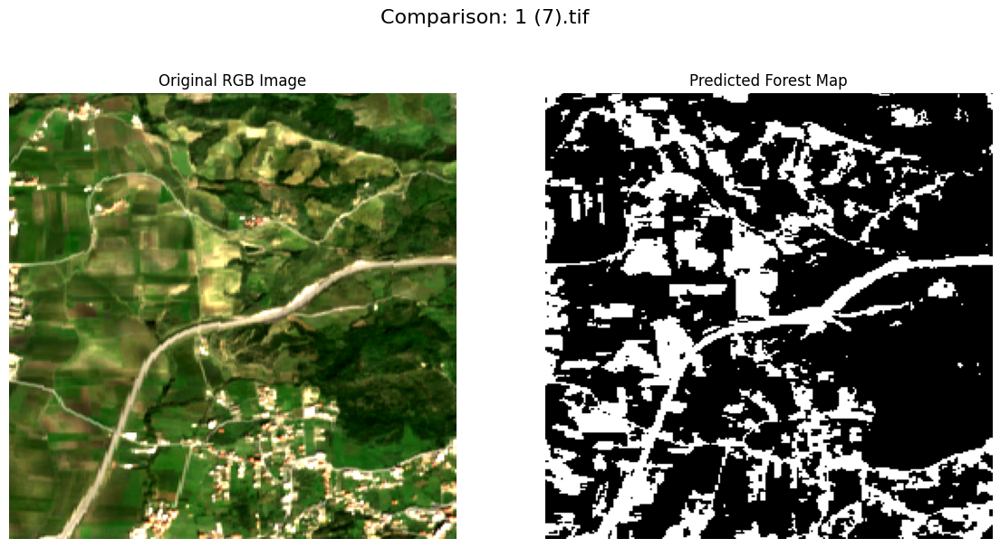

🖼️ Processing 1 (8).tif and 1 (8).csv


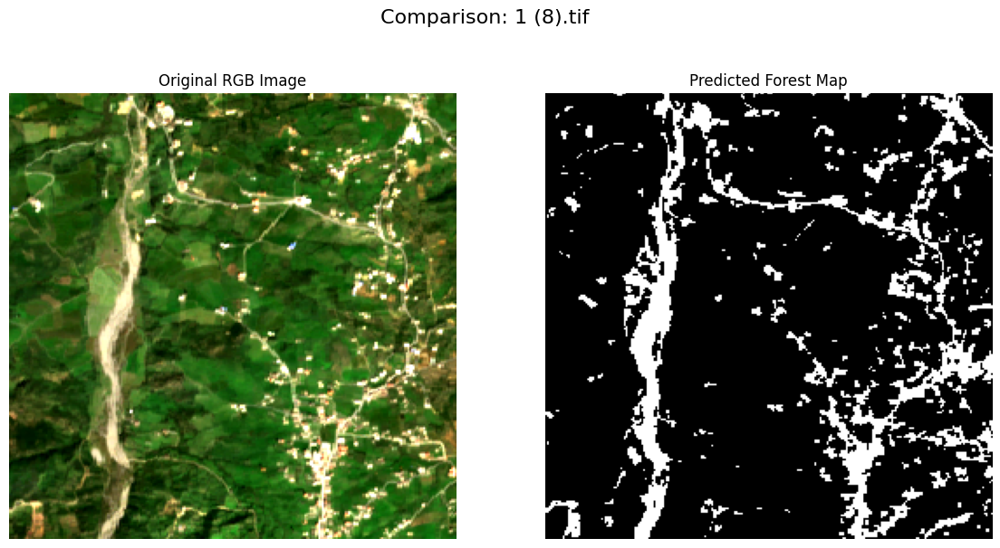

🖼️ Processing 1 (9).tif and 1 (9).csv


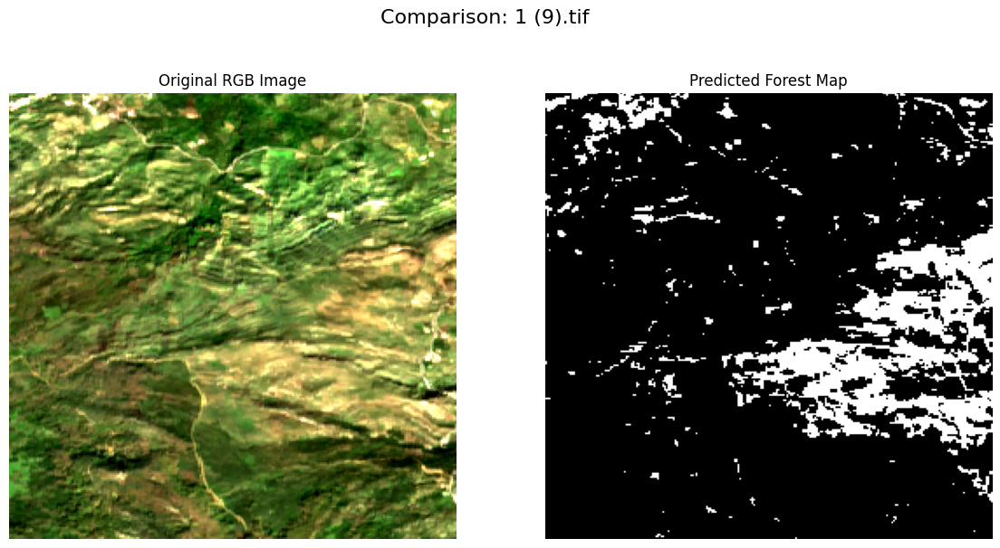

In [6]:
import os
import rasterio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

# --- 1. Load the model ---
xgb_clf_imp = xgb.XGBClassifier()
xgb_clf_imp.load_model('/content/final_model.json')
print("✅ Model loaded!")

# --- 2. Set your folders ---
tif_folder = '/content/drive/MyDrive/Validation_data'
csv_folder = '/content/drive/MyDrive/Test_Csv'

# --- 3. List all TIF and CSV files ---
tif_files = sorted([f for f in os.listdir(tif_folder) if f.endswith('.tif')])
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith('.csv')])

# --- 4. Loop through files ---
for tif_file, csv_file in zip(tif_files, csv_files):
    print(f"🖼️ Processing {tif_file} and {csv_file}")

    # --- Load the TIF image ---
    tif_path = os.path.join(tif_folder, tif_file)
    with rasterio.open(tif_path) as src:
        bands = src.read()  # (bands, height, width)

    # --- Create the RGB image (B4, B3, B2) ---
    rgb = np.stack([
        bands[3-1],  # B4 (Red)
        bands[2-1],  # B3 (Green)
        bands[1-1]   # B2 (Blue)
    ], axis=-1)

    # Normalize for visualization
    rgb_min, rgb_max = np.percentile(rgb, (2, 98))
    rgb = np.clip((rgb - rgb_min) / (rgb_max - rgb_min), 0, 1)

    # --- Load the CSV for prediction ---
    csv_path = os.path.join(csv_folder, csv_file)
    df_image = pd.read_csv(csv_path)

    # Drop the X column if exists
    if 'X' in df_image.columns:
        df_image = df_image.drop(columns=['X'])

    # Select important features
    important_features = ['band_12', 'band_7', 'band_3', 'band_6']
    X_image = df_image[important_features]

    # Predict
    y_pred = xgb_clf_imp.predict(X_image)

    # Reconstruct the prediction image
    height = bands.shape[1]
    width = bands.shape[2]
    prediction_image = y_pred.reshape((height, width))

    # Invert prediction if needed (to match colors)
    prediction_image = 1 - prediction_image

    # --- 5. Plot the RGB and Prediction side by side ---
    fig, axs = plt.subplots(1, 2, figsize=(14, 7))

    axs[0].imshow(rgb)
    axs[0].set_title('Original RGB Image')
    axs[0].axis('off')

    axs[1].imshow(prediction_image, cmap='gray', vmin=0, vmax=1)
    axs[1].set_title('Predicted Forest Map')
    axs[1].axis('off')

    plt.suptitle(f'Comparison: {tif_file}', fontsize=16)
    plt.show()


In [7]:
import os
import rasterio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb

# --- 1. Load the model ---
xgb_clf_imp = xgb.XGBClassifier()
xgb_clf_imp.load_model('/content/final_model.json')
print("✅ Model loaded!")

# --- 2. Set your folders ---
tif_folder = '/content/drive/MyDrive/Validation_data'
csv_folder = '/content/drive/MyDrive/Test_Csv'
output_folder = '/content/drive/MyDrive/output_tif'

os.makedirs(output_folder, exist_ok=True)  # Create output folder if it doesn't exist

# --- 3. List all TIF and CSV files ---
tif_files = sorted([f for f in os.listdir(tif_folder) if f.endswith('.tif')])
csv_files = sorted([f for f in os.listdir(csv_folder) if f.endswith('.csv')])

# --- 4. Loop through files ---
for tif_file, csv_file in zip(tif_files, csv_files):
    print(f"🖼️ Processing {tif_file} and {csv_file}")

    # --- Load the TIF image ---
    tif_path = os.path.join(tif_folder, tif_file)
    with rasterio.open(tif_path) as src:
        bands = src.read()  # (bands, height, width)
        meta = src.meta.copy()  # save metadata for later

    # --- Create the RGB image (B4, B3, B2) ---
    rgb = np.stack([
        bands[3-1],  # B4 (Red)
        bands[2-1],  # B3 (Green)
        bands[1-1]   # B2 (Blue)
    ], axis=-1)

    # Normalize RGB to [0, 1] for visualization
    rgb_min = np.min(rgb)
    rgb_max = np.max(rgb)
    rgb_normalized = (rgb - rgb_min) / (rgb_max - rgb_min)

    # --- Load the CSV for prediction ---
    csv_path = os.path.join(csv_folder, csv_file)
    df_image = pd.read_csv(csv_path)

    if 'X' in df_image.columns:
        df_image = df_image.drop(columns=['X'])

    important_features = ['band_12', 'band_7', 'band_3', 'band_6']
    X_image = df_image[important_features]

    # --- Predict ---
    y_pred = xgb_clf_imp.predict(X_image)

    # --- Reconstruct the prediction image ---
    height, width = bands.shape[1], bands.shape[2]
    prediction_image = y_pred.reshape((height, width))
    prediction_image = 1 - prediction_image  # Invert if needed

    # --- Save the prediction as GeoTIFF ---
    output_tif_path = os.path.join(output_folder, tif_file.replace('.tif', '_predicted.tif'))

    meta.update({
        'count': 1,        # only 1 band now
        'dtype': 'uint8'   # binary output
    })

    with rasterio.open(output_tif_path, 'w', **meta) as dst:
        dst.write(prediction_image.astype(np.uint8), 1)

    print(f"✅ Saved prediction GeoTIFF: {output_tif_path}")


✅ Model loaded!
🖼️ Processing 1 (1).tif and 1 (1).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (1)_predicted.tif
🖼️ Processing 1 (10).tif and 1 (10).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (10)_predicted.tif
🖼️ Processing 1 (11).tif and 1 (11).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (11)_predicted.tif
🖼️ Processing 1 (12).tif and 1 (12).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (12)_predicted.tif
🖼️ Processing 1 (13).tif and 1 (13).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (13)_predicted.tif
🖼️ Processing 1 (14).tif and 1 (14).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (14)_predicted.tif
🖼️ Processing 1 (15).tif and 1 (15).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (15)_predicted.tif
🖼️ Processing 1 (16).tif and 1 (16).csv
✅ Saved prediction GeoTIFF: /content/drive/MyDrive/output_tif/1 (16)_predicted.tif
🖼️ 

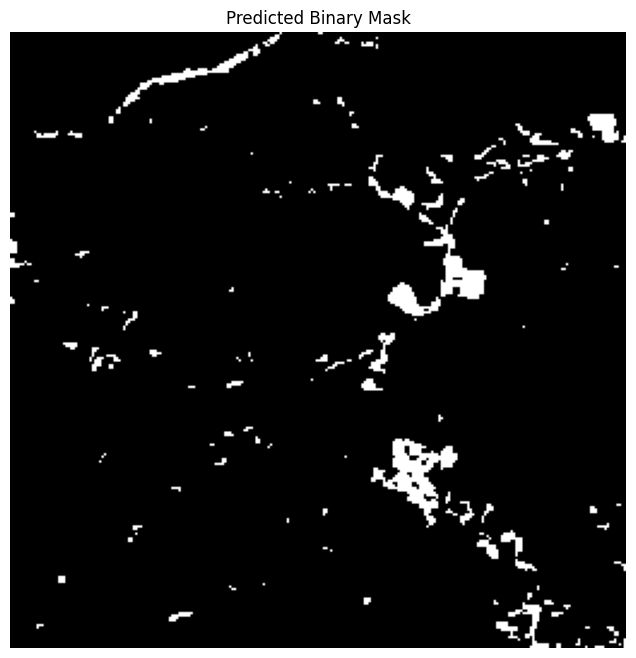

In [8]:
import rasterio
import matplotlib.pyplot as plt

# Path to your result tif
result_tif_path = '/content/drive/MyDrive/output_tif/1 (19)_predicted.tif'

# Open the result TIF
with rasterio.open(result_tif_path) as src:
    mask = src.read(1)  # Read the first band (binary mask)

# Plot it
plt.figure(figsize=(8, 8))
plt.imshow(mask, cmap='gray', vmin=0, vmax=1)
plt.title('Predicted Binary Mask')
plt.axis('off')
plt.show()


In [11]:
import os

# Path where you want to create the folder
folder_path = "/content/drive/MyDrive/Results_csv"

# Create the folder (and intermediate folders if needed)
os.makedirs(folder_path, exist_ok=True)

print(f"✅ Folder created at: {folder_path}")

✅ Folder created at: /content/drive/MyDrive/Results_csv


In [15]:
import os
import rasterio
import pandas as pd
import numpy as np

# Path to your folder with predicted TIFs (only 1 band)
pred_tif_folder = '/content/drive/MyDrive/output_tif'

# Path to save the labels CSVs
labels_csv_folder = '/content/drive/MyDrive/Results_csv'

# Create output folder if it doesn't exist
os.makedirs(labels_csv_folder, exist_ok=True)

# Loop through all .tif files
for filename in os.listdir(pred_tif_folder):
    if filename.endswith('.tif') or filename.endswith('.tiff'):
        tif_path = os.path.join(pred_tif_folder, filename)

        with rasterio.open(tif_path) as src:
            band = src.read(1)  # read the first band only (shape: height, width)

        h, w = band.shape
        print(f"Processing {filename}: height={h}, width={w}")

        # Flatten the band to (height*width,)
        flattened = band.flatten()

        # Normalize if needed (depends if values are 0/255 or already 0/1)
        flattened = np.where(flattened == 0, 1, 0)  # black=1, white=0

        # Save as CSV
        label_df = pd.DataFrame({'label': flattened})

        # Save CSV with same name
        csv_filename = os.path.splitext(filename)[0] + '.csv'
        csv_path = os.path.join(labels_csv_folder, csv_filename)
        label_df.to_csv(csv_path, index=False)

        print(f"✅ Saved labels to {csv_path}")


Processing 1 (1)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (1)_predicted.csv
Processing 1 (10)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (10)_predicted.csv
Processing 1 (11)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (11)_predicted.csv
Processing 1 (12)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (12)_predicted.csv
Processing 1 (13)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (13)_predicted.csv
Processing 1 (14)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (14)_predicted.csv
Processing 1 (15)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Results_csv/1 (15)_predicted.csv
Processing 1 (16)_predicted.tif: height=256, width=256
✅ Saved labels to /content/drive/MyDrive/Res